# Platform Transaction Demand Analysis

## Objectives

This project studies **daily platform transaction demand** using transaction, customer, Colombian public-holiday and TRM exchange-rate data.

The notebook follows a clear flow:

1. **prepare and integrate the data** so the source data is reliable;
2. **build a daily analytical dataset** and define Low / Medium / High demand;
3. **create leakage-safe historical features** using only information available before each demand date;
4. **explore the data** to understand when High demand happens and what signals may be useful;
5. **train and compare four classification models** to test whether the historical signals can help classify future demand.

## Core data-story question

> **When does High demand occur, what conditions are associated with it, and which historical signals are visible before it happens?**

## Predictive question

> **Can historical information available before a date help predict whether that date will have Low, Medium or High platform transaction demand?**

### Hypothesis

> **High-demand days can be detected using leakage-safe historical signals from recent transaction demand, calendar patterns, transaction behaviour and type composition, active-customer activity, engagement, product adoption, customer composition and market context. Combining these signals should provide useful classification of future Low, Medium and High demand, with particular attention to High-demand Recall and Macro F1.**

## Notebook flow

```text
1. Data Collection
2. Data Preparation and Validation
3. Data Integration
4. Daily Analytical Dataset + Demand Target
5. Leakage-Safe Historical Feature Engineering
6. Deep Data Exploration / Data Story
7. Train Models
8. Model Comparison and Hypothesis Assessment
9. Conclusion, Limitations and Recommendations
10. Hypothesis-Supporting Data Dashboard
```

### How to read the analysis

Section 6 uses two types of evidence:

- **same-day descriptive evidence** explains what Low, Medium and High demand days look like;
- **historical evidence** examines signals that were already available before the demand date.

The descriptive findings help explain the business story, while the historical findings justify the predictor set. **Section 8 is the actual out-of-sample test of the hypothesis.**

### Dashboard Link: 
https://dbc-ab5a7c34-858f.cloud.databricks.com/dashboardsv3/01f1992cc90b1c90a07e73a446229781/published?o=7474654938875323


# 1. Data Collection and Loading

The project uses **four structured CSV files from three external data sources**.

### Source 1 — COFINFAD: Colombian Fintech Financial Analytics Dataset

- **Source platform:** Mendeley Data
- **Source URL:** https://data.mendeley.com/datasets/mhb4zn3258/1
- **Files:** `customer_data.csv`, `transactions_data.csv`
- **Collection method:** Downloaded from the repository and uploaded to a Databricks Unity Catalog Volume.
- **Purpose:**
  - `customer_data.csv` provides customer information for customer-activity, engagement, product-adoption and customer-composition features;
  - `transactions_data.csv` provides dated transaction activity used to build daily platform demand.

### Source 2 — Colombia Public Holidays 2023

- **Source platform:** Colombia Calendario
- **Source URL:** https://colombiacalendario.com/en/2023
- **File:** `2023_Colombia_Public_Holidays.csv`
- **Collection method:** Downloaded as CSV and uploaded to the Databricks Unity Catalog Volume.
- **Purpose:** Adds calendar context so public-holiday demand can be compared with non-holiday demand.

### Source 3 — Historical Representative Market Exchange Rate (TRM)

- **Source platform:** Datos Abiertos Colombia
- **Source provider:** Superintendencia Financiera de Colombia
- **Source URL:** https://www.datos.gov.co/Econom-a-y-Finanzas/Tasa-de-Cambio-Representativa-del-Mercado-Historic/mcec-87by
- **File:** `TRM_Historical.csv`
- **Collection method:** Exported as CSV and uploaded to the Databricks Unity Catalog Volume.
- **Purpose:** Adds historical Colombian peso–US dollar market context.

### Storage and processing

The original files are kept unchanged in:

`/Volumes/workspace/it3388_bdmpj/data/`

PySpark is used to load, inspect, clean, validate, transform and integrate the source data. The much smaller daily modelling table is converted to Pandas only after the large transaction-level processing is complete.

Source row and column counts are checked before cleaning so later changes can be traced. The main integration keys are:

- customers + transactions → `customer_id`;
- holidays → transaction date;
- TRM → the validity period containing each transaction date.

This provides a traceable path from the original files to the final modelling dataset.


In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

base_path = "/Volumes/workspace/it3388_bdmpj/data/"

customersDF = (
    spark.read.option("header", True).option("inferSchema", True)
    .csv(base_path + "customer_data.csv")
)

transactionsDF = (
    spark.read.option("header", True).option("inferSchema", True)
    .csv(base_path + "transactions_data.csv")
)

holidayDF = (
    spark.read.option("header", True).option("inferSchema", True)
    .csv(base_path + "2023_Colombia_Public_Holidays.csv")
)

trmDF = (
    spark.read.option("header", True).option("inferSchema", True)
    .csv(base_path + "TRM_Historical.csv")
)

sources = {
    "Customer": customersDF,
    "Transaction": transactionsDF,
    "Holiday": holidayDF,
    "TRM": trmDF
}

sourceSummary = [
    (name, df.count(), len(df.columns))
    for name, df in sources.items()
]

display(
    spark.createDataFrame(
        sourceSummary,
        ["source", "rows", "columns"]
    )
)


source,rows,columns
Customer,48723,54
Transaction,3159157,4
Holiday,18,5
TRM,8318,4


## 1.1 Big Data Characteristics — 4Vs

The final modelling table contains only 332 usable dates, but it is created from much larger multi-source data. The 4Vs are therefore considered at the **source and processing level**, not only at the final daily level.

| Big Data characteristic | Evidence in this project |
|---|---|
| **Volume** | The raw data contains more than **3.15 million transaction records** and **48,000+ customer records**. PySpark is used for large-scale loading, validation, joins and aggregation before conversion to Pandas. |
| **Variety** | Three external sources contribute different information: fintech transaction/customer behaviour, public-holiday context and TRM market data. |
| **Velocity** | The transaction data is time-based and changes across dates. This project uses historical batch files rather than live streaming, so time order is preserved through lag/rolling features and a chronological train/test split. |
| **Veracity** | Data quality is checked through duplicate removal, missing-value checks, type/range validation, join audits, TRM coverage checks and leakage controls. |

This allows the model to use a compact daily table while still being built from large, multi-source transactional data.


# 2. Data Preparation and Quality Validation

The project focuses on **daily platform transaction demand**, so only variables that support the descriptive analysis or predictive task are retained.

## 2.0 Inclusion and Exclusion Rationale

### Included variables

| Variable group | Selected variables | Why they are included |
|---|---|---|
| Join identifier | `customer_id` | Links customer and transaction records and supports customer-level aggregation. |
| Transaction activity | `date`, `amount`, `type` | Used to build daily demand, transaction-value behaviour and transaction-type composition. |
| Customer composition | `customer_segment` | Used to describe and build historical customer-composition features. |
| Product adoption | `active_products` | Represents product usage and supports a historical product-adoption signal. |
| Digital engagement | `app_logins_frequency` | Represents customer engagement and supports a historical engagement signal. |
| Credit activity | `credit_card`, `credit_utilization_ratio` | Adds customer financial-behaviour context and supports historical cardholder-utilisation features. |
| Calendar effects | Holiday date, name and type | Allows public-holiday and non-holiday demand to be compared using information known in advance. |
| Market context | TRM value and validity dates | Adds historical Colombian peso–US dollar market context. |

### Excluded variables

- Satisfaction, NPS, feedback, complaints, support, churn and customer-lifetime-value fields are excluded because they relate to different customer-level outcomes.
- Demographic fields are excluded because this analysis focuses on **platform activity and behaviour**, not demographic profiling.
- Customer-level transaction summaries are excluded because the dated transaction file already provides the more detailed transaction-level records needed for this analysis.
- Holiday `Description` is not needed because holiday name/type already provide the required context.
- Source `Weekday` is excluded because weekday is derived consistently from `transaction_date`.

> **Predictive-use rule:** same-day transaction and customer measures may be used to explain what a demand day looks like, but the model uses only calendar information known in advance and historical lag/rolling features created in Section 5.

### Preparation flow

1. remove exact duplicate rows;
2. keep only justified variables;
3. audit missing values;
4. treat credit-utilisation missingness using business meaning;
5. standardise categories and convert required fields;
6. validate numeric and date fields;
7. integrate the four source files.


In [0]:
# Fields needed by this individual analysis
customerColumns = [
    "customer_id",

    # Customer composition
    "customer_segment",

    # Product adoption and digital engagement
    "active_products",
    "app_logins_frequency",

    # Credit activity
    "credit_card",
    "credit_utilization_ratio"
]

transactionColumns = [
    "customer_id",
    "date",
    "amount",
    "type"
]

holidayColumns = [
    "Date",
    "Name",
    "Type"
]

trmColumns = [
    "VALOR",
    "UNIDAD",
    "VIGENCIADESDE",
    "VIGENCIAHASTA"
]

print("Selected customer fields:", customerColumns)
print("Selected transaction fields:", transactionColumns)


Selected customer fields: ['customer_id', 'customer_segment', 'active_products', 'app_logins_frequency', 'credit_card', 'credit_utilization_ratio']
Selected transaction fields: ['customer_id', 'date', 'amount', 'type']


## 2.1 Data Trust — Exact Duplicate Check

The transaction data does not contain a unique transaction ID, so an exact duplicate is defined as a row that is identical across the **full original transaction schema**.

Duplicates are removed **before selecting fewer columns**. This avoids incorrectly treating two valid rows as duplicates simply because they become identical after unused columns are removed.

The same full-row duplicate check is applied to all four source files, and the before/after row counts are shown so the cleaning effect is transparent.


In [0]:
cleanFullSources = {}
duplicateRows = []

for name, df in sources.items():
    before = df.count()
    cleaned = df.dropDuplicates()
    after = cleaned.count()

    cleanFullSources[name] = cleaned
    duplicateRows.append((name, before, after, before - after))

display(
    spark.createDataFrame(
        duplicateRows,
        ["source", "rows_before", "rows_after", "exact_duplicates_removed"]
    )
)

# Select analysis fields only after exact full-row duplicates are removed
customersCleanDF = cleanFullSources["Customer"].select(*customerColumns)
transactionsCleanDF = cleanFullSources["Transaction"].select(*transactionColumns)
holidayCleanDF = cleanFullSources["Holiday"].select(*holidayColumns)
trmCleanDF = cleanFullSources["TRM"].select(*trmColumns)


source,rows_before,rows_after,exact_duplicates_removed
Customer,48723,48723,0
Transaction,3159157,3159055,102
Holiday,18,18,0
TRM,8318,8318,0


## 2.2 Comprehensive missing-value audit

Missing data may appear as more than a true Spark `NULL`, so every selected field is checked for:

- Spark `NULL`;
- `NaN`;
- empty or whitespace-only strings;
- common placeholders such as `NA`, `N/A`, `null`, `none`, `missing`, `unknown`, `not applicable`, `?`, `-` and `--`.

Values are trimmed and normalised before checking so inconsistent forms such as `" NULL "` are still detected.

This step is an **audit, not an automatic deletion rule**. Any missing value is interpreted using the meaning of the field before a treatment is chosen.


In [0]:
missingTokens = [
    "",
    "na",
    "n/a",
    "n.a.",
    "n.a",
    "n\\a",
    "null",
    "none",
    "nan",
    "nil",
    "missing",
    "unknown",
    "not available",
    "not applicable",
    "?",
    "-",
    "--"
]

def missing_summary(source_name, df):
    total_rows = df.count()

    expressions = []
    for column in df.columns:
        normalised = F.lower(F.trim(F.col(column).cast("string")))

        is_missing = (
            F.col(column).isNull()
            | normalised.isin(missingTokens)
        )

        expressions.append(
            F.sum(
                F.when(is_missing, 1).otherwise(0)
            ).alias(column)
        )

    counts = df.select(expressions).first().asDict()

    return [
        (
            source_name,
            column,
            int(counts[column] or 0),
            round((counts[column] or 0) / total_rows * 100, 2)
        )
        for column in df.columns
    ]

missingAuditRows = []

for name, df in {
    "Customer": customersCleanDF,
    "Transaction": transactionsCleanDF,
    "Holiday": holidayCleanDF,
    "TRM": trmCleanDF
}.items():
    missingAuditRows.extend(missing_summary(name, df))

missingAuditDF = spark.createDataFrame(
    missingAuditRows,
    ["source", "column", "potential_missing_count", "potential_missing_pct"]
)

print("Columns with potential missing values")
display(
    missingAuditDF
    .filter(F.col("potential_missing_count") > 0)
    .orderBy(F.desc("potential_missing_count"))
)


Columns with potential missing values


source,column,potential_missing_count,potential_missing_pct
Customer,credit_utilization_ratio,18263,37.48


### Missing-value decision — `credit_utilization_ratio`

The key question is not only **whether the value is missing**, but **why it is missing**.

`credit_utilization_ratio` is checked together with `credit_card` status. The results show that missing utilisation occurs only for customers without a credit card, so the value is **not applicable** rather than an unknown measurement.

The treatment is therefore:

- no credit card + missing utilisation → `0.0`;
- otherwise → convert the original utilisation value to numeric.

This is more meaningful than using a mean or median imputation. A final check confirms that no unresolved missing utilisation values remain.


In [0]:
creditText = F.lower(
    F.trim(F.col("credit_utilization_ratio").cast("string"))
)

creditMissing = (
    F.col("credit_utilization_ratio").isNull()
    | creditText.isin(missingTokens)
)

print("Missing credit utilisation by credit-card status")
display(
    customersCleanDF
    .groupBy("credit_card")
    .agg(
        F.count("*").alias("customers"),
        F.sum(
            F.when(creditMissing, 1).otherwise(0)
        ).alias("missing_credit_utilization")
    )
    .orderBy("credit_card")
)

customersPreparedDF = (
    customersCleanDF
    .withColumn(
        "credit_utilization_ratio",
        F.when(
            creditMissing & (F.col("credit_card") == False),
            F.lit(0.0)
        ).otherwise(
            F.expr("try_cast(credit_utilization_ratio AS DOUBLE)")
        )
    )
)

print(
    "Unresolved credit-utilisation values after treatment:",
    customersPreparedDF
    .filter(F.col("credit_utilization_ratio").isNull())
    .count()
)


Missing credit utilisation by credit-card status


credit_card,customers,missing_credit_utilization
false,18263,18263
true,30460,0


Unresolved credit-utilisation values after treatment: 0


## 2.3 Standardise and validate the retained customer predictors

The retained customer fields are cleaned before they are aggregated into daily features.

### `customer_segment`

Segment labels are trimmed, repeated spaces are reduced and capitalisation is standardised. Any unexpected blank value is labelled `Unknown`.

### `active_products` and `app_logins_frequency`

Both fields are converted to numeric values using `try_cast`. Invalid values become null and can therefore be detected instead of causing an uncontrolled conversion error.

### Why these customer variables are retained

The hypothesis includes customer activity, engagement, product adoption and customer composition as possible historical signals. The raw customer fields are therefore converted into more meaningful daily and historical features:

- each customer contributes only once per date when customer-level statistics are calculated;
- activity, engagement and product usage are smoothed using **previous-7-day averages**;
- customer segments become active-customer composition shares;
- credit utilisation is calculated among **cardholders only** before being converted into a historical feature.

This keeps the customer features relevant to the hypothesis while reducing one-day noise and avoiding same-day leakage.


In [0]:
# BEFORE standardisation
print("Customer segments BEFORE standardisation:")
display(
    customersPreparedDF
    .groupBy("customer_segment")
    .count()
    .orderBy(F.desc("count"))
)


# Standardise customer segment
customersPreparedDF = (
    customersPreparedDF

    .withColumn(
        "customer_segment",
        F.when(
            F.col("customer_segment").isNull()
            | (F.trim(F.col("customer_segment")) == ""),
            F.lit("Unknown")
        ).otherwise(
            F.initcap(
                F.trim(
                    F.regexp_replace(
                        F.col("customer_segment"),
                        r"\s+",
                        " "
                    )
                )
            )
        )
    )

    # Safe numeric conversions
    .withColumn(
        "active_products",
        F.expr("try_cast(active_products AS DOUBLE)")
    )
    .withColumn(
        "app_logins_frequency",
        F.expr("try_cast(app_logins_frequency AS DOUBLE)")
    )
)


# AFTER standardisation
print("Customer segments AFTER standardisation:")
display(
    customersPreparedDF
    .groupBy("customer_segment")
    .count()
    .orderBy(F.desc("count"))
)


customerQualityChecks = [
    (
        "invalid/missing active_products",
        customersPreparedDF
        .filter(
            F.col("active_products").isNull()
            | (F.col("active_products") < 0)
        )
        .count()
    ),
    (
        "invalid/missing app_logins_frequency",
        customersPreparedDF
        .filter(
            F.col("app_logins_frequency").isNull()
            | (F.col("app_logins_frequency") < 0)
        )
        .count()
    ),
    (
        "credit utilisation outside 0-1",
        customersPreparedDF
        .filter(
            F.col("credit_utilization_ratio").isNotNull()
            & (
                (F.col("credit_utilization_ratio") < 0)
                | (F.col("credit_utilization_ratio") > 1)
            )
        )
        .count()
    )
]

display(
    spark.createDataFrame(
        customerQualityChecks,
        ["customer_check", "records_flagged"]
    )
)


Customer segments BEFORE standardisation:


customer_segment,count
occasional,19391
regular,14568
inactive,9904
power,4860


Customer segments AFTER standardisation:


customer_segment,count
Occasional,19391
Regular,14568
Inactive,9904
Power,4860


customer_check,records_flagged
invalid/missing active_products,0
invalid/missing app_logins_frequency,0
credit utilisation outside 0-1,0


## 2.4 Prepare integration fields and run compact validity checks

Before joining the sources, the required transaction, holiday and TRM fields are converted and checked.

The validation covers:

- unparseable transaction dates;
- non-numeric or non-positive transaction amounts;
- missing transaction types;
- unparseable holiday dates;
- non-numeric or non-positive TRM values;
- reversed TRM validity periods;
- duplicate holiday dates;
- overlapping TRM validity periods that could duplicate transactions during the range join.

Transaction amounts are **not automatically capped or imputed** because unusually large values may be genuine financial activity.

If any validation check returns unexpected records, they should be investigated before modelling rather than silently removed.


In [0]:
transactionsPreparedDF = (
    transactionsCleanDF
    .select(
        "customer_id",
        F.to_date("date").alias("transaction_date"),
        F.expr("try_cast(amount AS DOUBLE)").alias("transaction_amount"),
F.initcap(
    F.trim(
        F.regexp_replace(
            F.col("type"),
            r"\s+",
            " "
        )
    )
).alias("transaction_type")
    )
)

print("Standardised transaction types:")
display(
    transactionsPreparedDF
    .select("transaction_type")
    .distinct()
    .orderBy("transaction_type")
)

holidayValidationDF = (
    holidayCleanDF
    .select(
        F.coalesce(
            F.to_date("Date"),
            F.to_date("Date", "d/M/yyyy"),
            F.to_date("Date", "dd/MM/yyyy")
        ).alias("holiday_date"),
        F.col("Name").alias("holiday_name"),
        F.col("Type").alias("holiday_type")
    )
)

trmValidationDF = (
    trmCleanDF
    .select(
        F.expr(
            """
            try_cast(
                regexp_replace(cast(VALOR as string), '[^0-9.-]', '')
                AS DOUBLE
            )
            """
        ).alias("exchange_rate"),
        F.col("UNIDAD").alias("currency_unit"),
        F.to_date("VIGENCIADESDE").alias("valid_from"),
        F.to_date("VIGENCIAHASTA").alias("valid_to")
    )
)

qualityChecks = [
    (
        "Transaction",
        "invalid date",
        transactionsPreparedDF.filter(F.col("transaction_date").isNull()).count()
    ),
    (
        "Transaction",
        "invalid/missing amount",
        transactionsPreparedDF.filter(F.col("transaction_amount").isNull()).count()
    ),
    (
        "Transaction",
        "non-positive amount",
        transactionsPreparedDF.filter(F.col("transaction_amount") <= 0).count()
    ),
    (
        "Transaction",
        "missing type",
        transactionsPreparedDF.filter(F.col("transaction_type").isNull()).count()
    ),
    (
        "Holiday",
        "invalid date",
        holidayValidationDF.filter(F.col("holiday_date").isNull()).count()
    ),
    (
        "TRM",
        "invalid record",
        trmValidationDF.filter(
            F.col("exchange_rate").isNull()
            | (F.col("exchange_rate") <= 0)
            | F.col("valid_from").isNull()
            | F.col("valid_to").isNull()
            | (F.col("valid_to") < F.col("valid_from"))
        ).count()
    )
]

display(
    spark.createDataFrame(
        qualityChecks,
        ["source", "check", "records_flagged"]
    )
)


Standardised transaction types:


transaction_type
Deposit
Payment
Transfer
Withdrawal


source,check,records_flagged
Transaction,invalid date,0
Transaction,invalid/missing amount,0
Transaction,non-positive amount,0
Transaction,missing type,0
Holiday,invalid date,0
TRM,invalid record,0


In [0]:
# One holiday record per date
duplicateHolidayDates = (
    holidayValidationDF
    .groupBy("holiday_date")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

holidayPreparedDF = (
    holidayValidationDF
    .groupBy("holiday_date")
    .agg(
        F.concat_ws(" | ", F.sort_array(F.collect_set("holiday_name"))).alias("holiday_name"),
        F.concat_ws(" | ", F.sort_array(F.collect_set("holiday_type"))).alias("holiday_type")
    )
)

# Keep valid TRM records
trmPreparedDF = (
    trmValidationDF
    .filter(
        F.col("exchange_rate").isNotNull()
        & (F.col("exchange_rate") > 0)
        & F.col("valid_from").isNotNull()
        & F.col("valid_to").isNotNull()
        & (F.col("valid_to") >= F.col("valid_from"))
    )
    .dropDuplicates()
)

trmWindow = Window.orderBy("valid_from", "valid_to")

overlappingTRMPeriods = (
    trmPreparedDF
    .withColumn("previous_valid_to", F.lag("valid_to").over(trmWindow))
    .filter(
        F.col("previous_valid_to").isNotNull()
        & (F.col("valid_from") <= F.col("previous_valid_to"))
    )
    .count()
)

print("Duplicate holiday dates:", duplicateHolidayDates)
print("Overlapping TRM validity periods:", overlappingTRMPeriods)


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1160: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Duplicate holiday dates: 0
Overlapping TRM validity periods: 0


# 3. Data Integration

The cleaned sources are joined so each transaction can be enriched with customer, calendar and market information.

The integration is carried out in three steps:

1. **transactions + customers** using `customer_id`;
2. **+ public holidays** using transaction date;
3. **+ historical TRM** using the validity period that contains the transaction date.

### Data trust rule during integration

> **A contextual join should add information without unexpectedly removing or multiplying transaction rows.**

Row counts are checked before and after every join. Holiday data is reduced to one row per date, and TRM validity periods are checked for overlap before the range join.

These checks protect the transaction population from accidental one-to-many joins.


In [0]:
joinAudit = []

# 1. Transactions + customers
before = transactionsPreparedDF.count()

customerTransactionDF = (
    transactionsPreparedDF
    .join(
        customersPreparedDF.select(
            "customer_id",
            "customer_segment",
            "active_products",
            "app_logins_frequency",
            "credit_card",
            "credit_utilization_ratio"
        ),
        on="customer_id",
        how="inner"
    )
)

after = customerTransactionDF.count()

joinAudit.append(
    (
        "Transactions + Customers",
        before,
        after,
        after - before
    )
)


In [0]:
# 2. Add public-holiday context
before = customerTransactionDF.count()

customerTransactionHolidayDF = (
    customerTransactionDF.alias("main")
    .join(
        holidayPreparedDF.alias("holiday"),
        F.col("main.transaction_date") == F.col("holiday.holiday_date"),
        how="left"
    )
    .select(
        "main.*",
        F.col("holiday.holiday_name"),
        F.col("holiday.holiday_type"),
        F.when(
            F.col("holiday.holiday_date").isNotNull(),
            1
        ).otherwise(0).alias("is_public_holiday")
    )
)

after = customerTransactionHolidayDF.count()
joinAudit.append(("Add Holidays", before, after, after - before))


In [0]:
# 3. Add the TRM record valid on each transaction date
before = customerTransactionHolidayDF.count()

integratedDF = (
    customerTransactionHolidayDF.alias("main")
    .join(
        trmPreparedDF.alias("trm"),
        (
            (F.col("main.transaction_date") >= F.col("trm.valid_from"))
            & (F.col("main.transaction_date") <= F.col("trm.valid_to"))
        ),
        how="left"
    )
    .select(
        "main.*",
        F.col("trm.exchange_rate"),
        F.col("trm.currency_unit")
    )
)

after = integratedDF.count()
joinAudit.append(("Add TRM", before, after, after - before))

display(
    spark.createDataFrame(
        joinAudit,
        ["join_step", "rows_before", "rows_after", "row_difference"]
    )
)

print(
    "Transaction dates without a TRM match:",
    integratedDF
    .filter(F.col("exchange_rate").isNull())
    .select("transaction_date")
    .distinct()
    .count()
)


join_step,rows_before,rows_after,row_difference
Transactions + Customers,3159055,3159055,0
Add Holidays,3159055,3159055,0
Add TRM,3159055,3159055,0


Transaction dates without a TRM match: 0


### Integration and Data Trust Result

If every `row_difference` is `0`, the joins have preserved the cleaned transaction population.

A zero count for transaction dates without a TRM match also confirms that the TRM source covers the transaction period.

The final integrated dataset now combines transaction activity with customer, holiday and market context. It is ready for:

- daily aggregation in Section 4;
- descriptive analysis in Section 6;
- leakage-safe historical feature engineering for modelling.


# 4. Daily Analytical Dataset and Demand Target

The business problem is defined at the **daily platform level**, so the transaction-level data is aggregated into one analytical row per date.

The daily dataset contains descriptive measures such as:

- transaction count and total value;
- transaction-type shares;
- active-customer count;
- transactions per active customer;
- digital engagement;
- product adoption;
- customer-segment composition;
- public-holiday status;
- TRM exchange rate.

The Low / Medium / High demand target is also created in this section.

These same-day measures are useful for explaining what different demand levels look like, but they are **not automatically used as predictors**. Section 5 converts the relevant information into calendar variables known in advance and historical lag/rolling features.

The first 28 dates are kept as history so complete rolling features can be created. The remaining dates form the common population used for exploration and modelling.


In [0]:
# ---------------------------------------------------------------
# Transaction-level data -> one transaction summary per date
# ---------------------------------------------------------------
dailyTransactionDF = (
    integratedDF
    .groupBy("transaction_date")
    .agg(
        F.count("*").alias("daily_transaction_count"),
        F.sum("transaction_amount").alias("daily_total_transaction_amount"),
        F.avg("transaction_amount").alias("daily_avg_transaction_amount"),
        F.expr(
            "percentile_approx(transaction_amount, 0.5)"
        ).alias("daily_median_transaction_amount"),

        # Same-day transaction composition for DESCRIPTIVE exploration.
        F.avg(
            F.when(
                F.col("transaction_type") == "Transfer", 1.0
            ).otherwise(0.0)
        ).alias("transfer_share"),

        F.avg(
            F.when(
                F.col("transaction_type") == "Payment", 1.0
            ).otherwise(0.0)
        ).alias("payment_share"),

        F.avg(
            F.when(
                F.col("transaction_type") == "Withdrawal", 1.0
            ).otherwise(0.0)
        ).alias("withdrawal_share"),

        F.avg(
            F.when(
                F.col("transaction_type") == "Deposit", 1.0
            ).otherwise(0.0)
        ).alias("deposit_share"),

        F.max("is_public_holiday").alias("is_public_holiday"),
        F.first(
            "exchange_rate",
            ignorenulls=True
        ).alias("exchange_rate")
    )
)

# ---------------------------------------------------------------
# One customer contribution per date
# ---------------------------------------------------------------
# A customer may make many transactions on one date.
# Deduplicate customer-date combinations before calculating
# customer composition so frequent transactors are not
# accidentally given extra weight.
customerDateDF = (
    integratedDF
    .select(
        "transaction_date",
        "customer_id",
        "customer_segment",
        "active_products",
        "app_logins_frequency",
        "credit_card",
        "credit_utilization_ratio"
    )
    .dropDuplicates(
        ["transaction_date", "customer_id"]
    )
)

dailyCustomerDF = (
    customerDateDF
    .groupBy("transaction_date")
    .agg(
        F.count("customer_id").alias(
            "active_customer_count"
        ),

        F.avg("app_logins_frequency").alias(
            "avg_app_logins_frequency"
        ),

        F.avg("active_products").alias(
            "avg_active_products"
        ),

        F.avg(
            F.when(
                F.col("credit_card") == True,
                F.col("credit_utilization_ratio")
            )
        ).alias(
            "avg_credit_utilization_cardholders"
        ),

        F.avg(
            F.when(
                F.col("customer_segment") == "Power",
                1.0
            ).otherwise(0.0)
        ).alias("power_customer_share"),

        F.avg(
            F.when(
                F.col("customer_segment") == "Inactive",
                1.0
            ).otherwise(0.0)
        ).alias("inactive_customer_share")
    )
)

dailyBaseDF = (
    dailyTransactionDF
    .join(
        dailyCustomerDF,
        on="transaction_date",
        how="inner"
    )
    .withColumn(
        "transactions_per_active_customer",
        (
            F.col("daily_transaction_count")
            / F.col("active_customer_count")
        )
    )
    .withColumn(
        "day_of_week",
        F.date_format(
            "transaction_date",
            "EEEE"
        )
    )
    .withColumn(
        "day_type",
        F.when(
            F.dayofweek("transaction_date").isin([1, 7]),
            F.lit("Weekend")
        ).otherwise(F.lit("Weekday"))
    )
    .withColumn(
        "holiday_status",
        F.when(
            F.col("is_public_holiday") == 1,
            F.lit("Public holiday")
        ).otherwise(F.lit("Non-holiday"))
    )
    .orderBy("transaction_date")
)

# Aggregation audit
originalTransactionCount = integratedDF.count()

representedTransactionCount = (
    dailyBaseDF
    .agg(
        F.sum("daily_transaction_count")
    )
    .first()[0]
)

print(
    "Original integrated transaction rows:",
    f"{originalTransactionCount:,}"
)
print(
    "Transactions represented in daily summaries:",
    f"{representedTransactionCount:,}"
)
print(
    "All transactions represented:",
    originalTransactionCount == representedTransactionCount
)
print(
    "Daily records before modelling-history requirement:",
    dailyBaseDF.count()
)

display(dailyBaseDF.limit(10))


Original integrated transaction rows: 3,159,055
Transactions represented in daily summaries: 3,159,055
All transactions represented: True
Daily records before modelling-history requirement: 360


transaction_date,daily_transaction_count,daily_total_transaction_amount,daily_avg_transaction_amount,daily_median_transaction_amount,transfer_share,payment_share,withdrawal_share,deposit_share,is_public_holiday,exchange_rate,active_customer_count,avg_app_logins_frequency,avg_active_products,avg_credit_utilization_cardholders,power_customer_share,inactive_customer_share,transactions_per_active_customer,day_of_week,day_type,holiday_status
2023-01-04,8782,3.36845473E10,3835635.083124573,1792650.0,0.4608289683443407,0.29674333864723296,0.1429059439763152,0.09952174903211114,0,4842.26,4724,22.23878069432684,2.1109229466553767,0.2853462863846973,0.09695173581710415,0.20279424216765454,1.859017781541067,Wednesday,Weekday,Non-holiday
2023-01-05,8726,2.82234257E10,3234405.8789823516,1487300.0,0.4577125830850332,0.3132019252807701,0.14107265642906258,0.08801283520513409,0,4924.0,4701,22.681344394809614,2.0887045309508614,0.2872067389138434,0.09955328653477984,0.2074026802807913,1.8562008083386514,Thursday,Weekday,Non-holiday
2023-01-06,8844,3.687476735E10,4169467.1359113525,1870350.0,0.4500226142017187,0.3152419719583899,0.14009497964721845,0.094640434192673,0,4989.58,4815,22.230944963655244,2.1148494288681206,0.290575069335883,0.10093457943925234,0.20332294911734164,1.8367601246105918,Friday,Weekday,Non-holiday
2023-01-07,8813,2.793728835E10,3170008.890275729,1490100.0,0.4637467377737433,0.29706115965051627,0.14626120503801202,0.09293089753772836,0,4885.66,4758,22.155107187894075,2.1040353089533417,0.2867838176356782,0.10046237915090374,0.2065994115174443,1.8522488440521228,Saturday,Weekend,Non-holiday
2023-01-08,8818,2.765612675E10,3136326.462916761,1437450.0,0.44533907915627124,0.3118621002494897,0.14334316171467454,0.09945565887956452,0,4885.66,4710,22.5380042462845,2.0798301486199575,0.2851636427150113,0.09363057324840764,0.21613588110403398,1.8721868365180467,Sunday,Weekend,Non-holiday
2023-01-09,8709,2.765386695E10,3175320.58215639,1498850.0,0.4516017912504306,0.3060052818922953,0.14743368928694453,0.09495923757032955,1,4885.66,4697,22.39131360442836,2.104534809452842,0.2899145417354502,0.1053864168618267,0.21034703001916116,1.8541622312114114,Monday,Weekday,Public holiday
2023-01-10,8984,2.85468273E10,3177518.621994657,1452300.0,0.45547640249332144,0.3077693677649154,0.14225289403383792,0.0945013357079252,0,4885.66,4895,22.24106230847804,2.0992849846782433,0.28436862422501996,0.10010214504596528,0.212461695607763,1.8353421859039836,Tuesday,Weekday,Non-holiday
2023-01-11,8645,3.3966045E10,3928981.4921920183,1775100.0,0.4537883169462117,0.3135916714864083,0.14621168305378832,0.08640832851359168,0,4807.85,4723,22.298327334321407,2.1213211941562564,0.2860049992061487,0.09908956171924624,0.21003599407156467,1.830404403980521,Wednesday,Weekday,Non-holiday
2023-01-12,8834,2.734160255E10,3095042.172288884,1411850.0,0.45392800543355216,0.3124292506225945,0.14251754584559656,0.09112519809825674,0,4748.54,4787,22.420513891790264,2.08543973260915,0.2867346355216107,0.10382285356172968,0.21600167119281388,1.8454146647169418,Thursday,Weekday,Non-holiday
2023-01-13,8615,4.94432723E10,5739207.4637260595,2624600.0,0.4567614625652931,0.30911201392919324,0.14242600116076612,0.09170052234474753,0,4692.04,4752,22.49473905723906,2.096801346801347,0.2868428771327049,0.09743265993265993,0.20496632996632996,1.8129208754208754,Friday,Weekday,Non-holiday


## 4.1 Define the prediction population

Some predictive features require up to **28 previous dates** of history.

The first 28 dates are therefore kept only as historical context and are excluded from the final prediction population.

This ensures that every analysed and modelled date has the required history available.


In [0]:
# Windows are defined here and reused later in predictive feature engineering.
dateWindow = Window.orderBy("transaction_date")
previous7Window = dateWindow.rowsBetween(-7, -1)
previous28Window = dateWindow.rowsBetween(-28, -1)

analysisEligibleDF = (
    dailyBaseDF
    .withColumn(
        "history_days_available",
        F.count(
            "daily_transaction_count"
        ).over(previous28Window)
    )
    .filter(
        F.col("history_days_available") == 28
    )
    .drop("history_days_available")
    .orderBy("transaction_date")
)

print(
    "Usable dates with complete 28-date history:",
    analysisEligibleDF.count()
)


Usable dates with complete 28-date history: 332


## 4.2 Create the Low / Medium / High demand target

The target is created before feature engineering so the same demand classes are used throughout exploration and modelling.

The two cut-offs are calculated using only the **earliest 70% of usable dates**:

- **Low** — daily transaction count at or below the lower cut-off;
- **Medium** — between the two cut-offs;
- **High** — above the upper cut-off.

Using only the earlier 70% prevents the later test period from influencing how the target is defined.

> These are **statistical demand classes for this project**, not real platform-capacity thresholds. Section 9 recommends replacing them with business-defined thresholds for operational use.


In [0]:
orderedAnalysisDF = analysisEligibleDF.withColumn(
    "time_order",
    F.row_number().over(
        Window.orderBy("transaction_date")
    )
)

totalRows = orderedAnalysisDF.count()
trainingRows = int(totalRows * 0.70)

trainingReferenceDF = orderedAnalysisDF.filter(
    F.col("time_order") <= trainingRows
)

lowThreshold, highThreshold = trainingReferenceDF.approxQuantile(
    "daily_transaction_count",
    [1/3, 2/3],
    0.0
)

targetDF = (
    orderedAnalysisDF
    .withColumn(
        "demand_class",
        F.when(
            F.col("daily_transaction_count") <= lowThreshold,
            "Low"
        )
        .when(
            F.col("daily_transaction_count") <= highThreshold,
            "Medium"
        )
        .otherwise("High")
    )
    .drop("time_order")
    .orderBy("transaction_date")
)

print(
    "Low / Medium threshold:",
    lowThreshold
)
print(
    "Medium / High threshold:",
    highThreshold
)

display(
    targetDF
    .groupBy("demand_class")
    .count()
    .orderBy("demand_class")
)


Low / Medium threshold: 8725.0
Medium / High threshold: 8804.0


demand_class,count
High,124
Low,106
Medium,102


# 5. Leakage-Safe Historical Feature Engineering

The model should only use information that would have been available **before the demand date**.

The notebook therefore separates two ideas:

> **What does a High-demand day look like?** — same-day descriptive evidence

> **What was already known before the High-demand day?** — leakage-safe predictive evidence

Every rolling window ends on the **previous date**, and every lag uses past information only. The target date's transaction or customer activity is never used as a predictor for that same date.


In [0]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dayOrder = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

classOrder = ["Low", "Medium", "High"]


## 5.1 Historical predictor families

The historical predictor set follows the same feature families stated in the hypothesis.

### Calendar information known in advance

- day of week;
- public-holiday status.

### Recent demand lags and trends

- previous-day transaction count;
- same weekday one week earlier;
- previous 7-date average;
- previous 28-date average;
- previous four same-weekday average;
- short-term versus long-term demand trend.

### Historical transaction behaviour and composition

- previous 7-date median transaction value;
- previous 7-date Transfer share;
- previous 7-date Payment share;
- previous 7-date Withdrawal share.

### Historical active-customer activity

- previous 7-date active-customer level;
- previous 7-date transactions per active customer.

### Historical engagement and product adoption

- previous 7-date app-login frequency;
- previous 7-date active products.

### Historical customer composition

- previous 7-date cardholder credit utilisation;
- previous 7-date Power-customer share;
- previous 7-date Inactive-customer share.

### Historical market context

- previous-date TRM;
- recent TRM change.

Together, these features cover the hypothesis while remaining leakage-safe.


In [0]:
featureDF = (
    dailyBaseDF

    # -----------------------------------------------------------
    # Complete-history requirement
    # -----------------------------------------------------------
    .withColumn(
        "history_days_available",
        F.count(
            "daily_transaction_count"
        ).over(previous28Window)
    )

    # -----------------------------------------------------------
    # Historical demand behaviour
    # -----------------------------------------------------------
    .withColumn(
        "previous_day_transaction_count",
        F.lag(
            "daily_transaction_count",
            1
        ).over(dateWindow)
    )
    .withColumn(
        "previous_7_day_transaction_count",
        F.lag(
            "daily_transaction_count",
            7
        ).over(dateWindow)
    )
    .withColumn(
        "previous_14_day_transaction_count",
        F.lag(
            "daily_transaction_count",
            14
        ).over(dateWindow)
    )
    .withColumn(
        "previous_21_day_transaction_count",
        F.lag(
            "daily_transaction_count",
            21
        ).over(dateWindow)
    )
    .withColumn(
        "previous_28_day_transaction_count",
        F.lag(
            "daily_transaction_count",
            28
        ).over(dateWindow)
    )
    .withColumn(
        "previous_7_day_avg_transaction_count",
        F.avg(
            "daily_transaction_count"
        ).over(previous7Window)
    )
    .withColumn(
        "previous_28_day_avg_transaction_count",
        F.avg(
            "daily_transaction_count"
        ).over(previous28Window)
    )
    .withColumn(
        "previous_4_same_weekday_avg_transaction_count",
        (
            F.col("previous_7_day_transaction_count")
            + F.col("previous_14_day_transaction_count")
            + F.col("previous_21_day_transaction_count")
            + F.col("previous_28_day_transaction_count")
        ) / F.lit(4.0)
    )
    .withColumn(
        "demand_trend_7_vs_28",
        (
            F.col("previous_7_day_avg_transaction_count")
            - F.col("previous_28_day_avg_transaction_count")
        )
    )

    # -----------------------------------------------------------
    # Historical transaction behaviour
    # -----------------------------------------------------------
    .withColumn(
        "previous_7_day_avg_median_transaction_amount",
        F.avg(
            "daily_median_transaction_amount"
        ).over(previous7Window)
    )
    .withColumn(
        "previous_7_day_avg_transfer_share",
        F.avg(
            "transfer_share"
        ).over(previous7Window)
    )
    .withColumn(
        "previous_7_day_avg_payment_share",
        F.avg(
            "payment_share"
        ).over(previous7Window)
    )
    .withColumn(
        "previous_7_day_avg_withdrawal_share",
        F.avg(
            "withdrawal_share"
        ).over(previous7Window)
    )

    # -----------------------------------------------------------
    # Historical market context
    # -----------------------------------------------------------
    .withColumn(
        "previous_day_exchange_rate",
        F.lag(
            "exchange_rate",
            1
        ).over(dateWindow)
    )
    .withColumn(
        "previous_1_vs_7_day_exchange_rate_change",
        (
            F.lag(
                "exchange_rate",
                1
            ).over(dateWindow)
            - F.lag(
                "exchange_rate",
                7
            ).over(dateWindow)
        )
    )

    # -----------------------------------------------------------
    # Historical customer behaviour
    # -----------------------------------------------------------
    .withColumn(
        "previous_7_day_avg_active_customer_count",
        F.avg(
            "active_customer_count"
        ).over(previous7Window)
    )
    .withColumn(
        "previous_7_day_avg_transactions_per_active_customer",
        F.avg(
            "transactions_per_active_customer"
        ).over(previous7Window)
    )
    .withColumn(
        "previous_7_day_avg_app_logins_frequency",
        F.avg(
            "avg_app_logins_frequency"
        ).over(previous7Window)
    )
    .withColumn(
        "previous_7_day_avg_active_products",
        F.avg(
            "avg_active_products"
        ).over(previous7Window)
    )
    .withColumn(
        "previous_7_day_avg_credit_utilization_cardholders",
        F.avg(
            "avg_credit_utilization_cardholders"
        ).over(previous7Window)
    )
    .withColumn(
        "previous_7_day_avg_power_customer_share",
        F.avg(
            "power_customer_share"
        ).over(previous7Window)
    )
    .withColumn(
        "previous_7_day_avg_inactive_customer_share",
        F.avg(
            "inactive_customer_share"
        ).over(previous7Window)
    )

    # Keep the same complete-history prediction population used throughout the analysis.
    .filter(
        F.col("history_days_available") == 28
    )
    .drop(
        "history_days_available"
    )
    .orderBy(
        "transaction_date"
    )
)

print(
    "Usable daily records after historical feature engineering:",
    featureDF.count()
)


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1160: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Usable daily records after historical feature engineering: 332


## 5.2 Attach the demand target

The Low / Medium / High target created in Section 4 is joined to the historical feature table using `transaction_date`.

Each modelling row therefore contains:

- the demand class that occurred on that date; and
- only the information that was available before that date.


In [0]:
featureWithTargetDF = (
    featureDF
    .join(
        targetDF.select(
            "transaction_date",
            "demand_class"
        ),
        on="transaction_date",
        how="inner"
    )
    .orderBy("transaction_date")
)

print(
    "Historical-feature rows with target:",
    featureWithTargetDF.count()
)


Historical-feature rows with target: 332


## 5.3 Final modelling dataset

The final modelling table is kept compact and interpretable. Its predictors cover the same information families used in the hypothesis.

| Feature family | Examples |
|---|---|
| **Calendar patterns** | weekday, public-holiday flag |
| **Recent demand** | previous-day count, rolling averages, same-weekday history, demand trend |
| **Transaction behaviour / type composition** | historical median value, Transfer / Payment / Withdrawal shares |
| **Active-customer activity** | historical active-customer level, transactions per active customer |
| **Engagement** | historical app-login frequency |
| **Product adoption** | historical active products |
| **Customer composition** | cardholder utilisation, Power-customer share, Inactive-customer share |
| **Market context** | historical TRM level and change |

Same-day descriptive measures remain available for Section 6, but they are **not used as same-day predictors**.


In [0]:
calendarPredictorColumns = [
    "day_of_week",
    "is_public_holiday"
]

demandMemoryPredictorColumns = [
    "previous_day_transaction_count",
    "previous_7_day_transaction_count",
    "previous_7_day_avg_transaction_count",
    "previous_28_day_avg_transaction_count",
    "previous_4_same_weekday_avg_transaction_count",
    "demand_trend_7_vs_28"
]

transactionBehaviourPredictorColumns = [
    "previous_7_day_avg_median_transaction_amount",
    "previous_7_day_avg_transfer_share",
    "previous_7_day_avg_payment_share",
    "previous_7_day_avg_withdrawal_share"
]

externalPredictorColumns = [
    "previous_day_exchange_rate",
    "previous_1_vs_7_day_exchange_rate_change"
]

customerPredictorColumns = [
    "previous_7_day_avg_active_customer_count",
    "previous_7_day_avg_transactions_per_active_customer",
    "previous_7_day_avg_app_logins_frequency",
    "previous_7_day_avg_active_products",
    "previous_7_day_avg_credit_utilization_cardholders",
    "previous_7_day_avg_power_customer_share",
    "previous_7_day_avg_inactive_customer_share"
]

predictorColumns = (
    calendarPredictorColumns
    + demandMemoryPredictorColumns
    + transactionBehaviourPredictorColumns
    + externalPredictorColumns
    + customerPredictorColumns
)

finalFeatureDF = (
    featureWithTargetDF
    .select(
        "transaction_date",

        # Outcomes retained for interpretation only
        "daily_transaction_count",
        "daily_total_transaction_amount",
        "daily_median_transaction_amount",

        *predictorColumns,
        "demand_class"
    )
    .orderBy("transaction_date")
)

print(
    "Final daily records:",
    finalFeatureDF.count()
)

print(
    "Predictor columns:",
    len(predictorColumns)
)

print(
    "Duplicated dates:",
    finalFeatureDF
    .groupBy("transaction_date")
    .count()
    .filter(
        F.col("count") > 1
    )
    .count()
)

display(
    finalFeatureDF.limit(10)
)


Final daily records: 332
Predictor columns: 21
Duplicated dates: 0


transaction_date,daily_transaction_count,daily_total_transaction_amount,daily_median_transaction_amount,day_of_week,is_public_holiday,previous_day_transaction_count,previous_7_day_transaction_count,previous_7_day_avg_transaction_count,previous_28_day_avg_transaction_count,previous_4_same_weekday_avg_transaction_count,demand_trend_7_vs_28,previous_7_day_avg_median_transaction_amount,previous_7_day_avg_transfer_share,previous_7_day_avg_payment_share,previous_7_day_avg_withdrawal_share,previous_day_exchange_rate,previous_1_vs_7_day_exchange_rate_change,previous_7_day_avg_active_customer_count,previous_7_day_avg_transactions_per_active_customer,previous_7_day_avg_app_logins_frequency,previous_7_day_avg_active_products,previous_7_day_avg_credit_utilization_cardholders,previous_7_day_avg_power_customer_share,previous_7_day_avg_inactive_customer_share,demand_class
2023-02-01,8781,3.394549435E10,1752750.0,Wednesday,0,8648,8808,8728.57142857143,8772.464285714286,8750.75,-43.89285714285688,1817057.142857143,0.4551430559067686,0.30460719951165743,0.1446419121648938,4632.2,86.26000000000022,4721.142857142857,1.8489706619954371,22.285617670939143,2.108523527187787,0.2881364067182405,0.09875432596098434,0.20412003085819472,Medium
2023-02-02,8728,2.817239555E10,1484300.0,Thursday,0,8781,8639,8724.714285714286,8772.42857142857,8741.75,-47.714285714284415,1813164.2857142857,0.45387958469878464,0.30487005626973535,0.145290179866989,4648.7,109.78999999999996,4726.571428571428,1.8460710574640082,22.319185183789262,2.103544348347877,0.28796260123602907,0.0991229101015643,0.2060667981832144,Medium
2023-02-03,8833,3.55481883E10,1890950.0,Friday,0,8728,8774,8737.42857142857,8772.5,8742.75,-35.07142857142935,1815985.7142857143,0.4532958728202168,0.30501902132664244,0.1451757538623861,4639.04,107.28999999999996,4724.571428571428,1.849571549438681,22.324424169641762,2.1029837022573585,0.28822434744859343,0.09938000170405238,0.20654902110586537,High
2023-02-04,8787,2.802173265E10,1490900.0,Saturday,0,8833,8825,8745.857142857143,8772.107142857143,8795.75,-26.25,1806250.0,0.4514147037341196,0.3064788230184213,0.14552478646538086,4584.44,35.9399999999996,4732.0,1.8484575695887993,22.30006574502488,2.1030786044904186,0.28827677225723125,0.0987175004541451,0.20742995373021905,Medium
2023-02-05,8893,2.88019298E10,1465000.0,Sunday,0,8787,8631,8740.42857142857,8771.17857142857,8766.5,-30.75,1730964.2857142857,0.45173074030575006,0.30557849552771155,0.14658698989612318,4669.74,121.23999999999978,4715.714285714285,1.853628075457154,22.242644816857172,2.102915828141822,0.2890536263800109,0.09985794674729871,0.20651823020364746,High
2023-02-06,8729,2.8141008E10,1477900.0,Monday,0,8893,8775,8777.857142857143,8773.857142857143,8777.25,4.0,1655842.857142857,0.4519090263126459,0.3063930878685796,0.14595599169852772,4669.74,121.23999999999978,4734.571428571428,1.8540789380900724,22.272112815143043,2.100477597079933,0.2898342130249573,0.0994597626714441,0.20762756174122618,Medium
2023-02-07,8719,2.81744185E10,1478250.0,Tuesday,0,8729,8648,8771.285714285714,8774.57142857143,8832.5,-3.285714285715585,1572492.857142857,0.45193918602661814,0.3061325516566172,0.14621112486235602,4669.74,37.539999999999964,4723.285714285715,1.8571196651691972,22.270895575416564,2.103025943912791,0.2892780470339179,0.09839717356829591,0.20818041479870636,Low
2023-02-08,8691,3.36715695E10,1771300.0,Wednesday,0,8719,8781,8781.42857142857,8765.107142857143,8750.5,16.321428571427532,1577150.0,0.45354900310545154,0.3049704117439241,0.14589175061928072,4776.25,127.55000000000018,4728.428571428572,1.85724717235796,22.331078211251015,2.0962618481406095,0.28864956005748693,0.09920357885262414,0.20838069744007673,Low
2023-02-09,8678,2.766021705E10,1485600.0,Thursday,0,8691,8728,8768.57142857143,8766.75,8742.25,1.821428571429351,1579800.0,0.453948947174606,0.3048776335703373,0.1462243110370299,4775.99,136.94999999999982,4712.285714285715,1.860813011863182,22.33417856874517,2.1004848720199343,0.289007125948

In [0]:
# Convert only the compact final modelling table to Pandas.

demandDF = (
    finalFeatureDF
    .toPandas()
)

demandDF["transaction_date"] = pd.to_datetime(
    demandDF["transaction_date"]
)

demandDF = (
    demandDF
    .sort_values("transaction_date")
    .reset_index(drop=True)
)

demandDF["day_of_week"] = pd.Categorical(
    demandDF["day_of_week"],
    categories=dayOrder,
    ordered=True
)

visualisationDF = demandDF.copy()

print(
    "Final modelling dataset:",
    demandDF.shape
)


Final modelling dataset: (332, 26)


# 6. Deep Data Exploration — Understanding Daily Demand

This section builds the data story before modelling. It answers three questions:

> **When does High demand happen? What is different on High-demand days? Which useful signals were visible beforehand?**

The exploration moves from simple description to predictive evidence:

1. understand the demand classes;
2. examine how demand changes over time;
3. check calendar patterns;
4. compare what happens on Low, Medium and High demand days;
5. examine leakage-safe historical signals;
6. use Section 8 to test whether the combined signals are useful out of sample.

> **Important:** Sections 6.1–6.3 use same-day information for explanation only. Section 6.4 uses historical information that could actually be available before the demand date. These relationships show association, not causation.


In [0]:
# Build one Pandas table for the Section 6 exploration.
# It contains same-day descriptive variables, historical predictors and the target.

storyDF = (
    featureWithTargetDF
    .orderBy("transaction_date")
    .toPandas()
)

storyDF["transaction_date"] = pd.to_datetime(
    storyDF["transaction_date"]
)

storyDF["demand_class"] = pd.Categorical(
    storyDF["demand_class"],
    categories=classOrder,
    ordered=True
)

storyDF["day_of_week"] = pd.Categorical(
    storyDF["day_of_week"],
    categories=dayOrder,
    ordered=True
)

storyDF["is_high_demand"] = (
    storyDF["demand_class"].astype(str) == "High"
).astype(int)

storyDF["holiday_status"] = np.where(
    storyDF["is_public_holiday"].astype(int) == 1,
    "Public holiday",
    "Non-holiday"
)

storyDF["day_type"] = np.where(
    storyDF["day_of_week"].astype(str).isin(
        ["Saturday", "Sunday"]
    ),
    "Weekend",
    "Weekday"
)

# Descriptive day-to-day movement. This is not used as a same-day predictor.
storyDF["daily_transaction_count_change"] = (
    storyDF["daily_transaction_count"].diff()
)

storyDF["absolute_daily_transaction_count_change"] = (
    storyDF["daily_transaction_count_change"].abs()
)

storyDF["demand_movement"] = np.select(
    [
        storyDF["daily_transaction_count_change"] > 0,
        storyDF["daily_transaction_count_change"] < 0
    ],
    ["Increase", "Decrease"],
    default="No change"
)

print("Exploration dataset:", storyDF.shape)
print(
    "Date range:",
    storyDF["transaction_date"].min().date(),
    "to",
    storyDF["transaction_date"].max().date()
)

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1160: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Exploration dataset: (332, 48)
Date range: 2023-02-01 to 2023-12-29


## 6.1 Demand overview

Before looking for possible drivers of High demand, the target itself is examined.

The first two charts answer:

- **How common are Low, Medium and High demand days?**
- **How does daily transaction demand change across 2023?**


demand_class,days,share_pct
Low,106,31.93
Medium,102,30.72
High,124,37.35


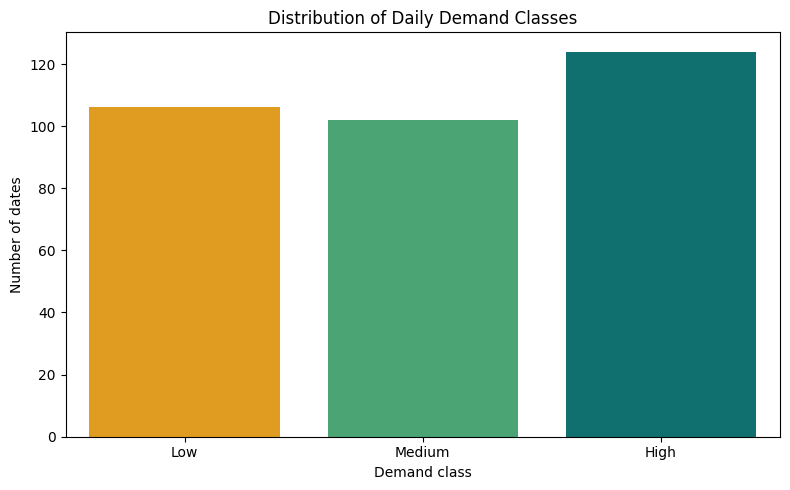

In [0]:
# -----------------------------------------------------------
# Chart 1 — Demand-class distribution
# -----------------------------------------------------------

classSummary = (
    storyDF["demand_class"]
    .value_counts()
    .reindex(classOrder)
    .rename_axis("demand_class")
    .reset_index(name="days")
)

classSummary["share_pct"] = (
    classSummary["days"]
    / len(storyDF)
    * 100
)

display(classSummary.round(2))

# Consistent colours for demand classes
demandPalette = {
    "Low": "orange",
    "Medium": "mediumseagreen",
    "High": "teal"
}

plt.figure(figsize=(8, 5))

sns.barplot(
    data=classSummary,
    x="demand_class",
    y="days",
    order=classOrder,
    hue="demand_class",
    palette=demandPalette,
    legend=False
)

plt.title("Distribution of Daily Demand Classes")
plt.xlabel("Demand class")
plt.ylabel("Number of dates")
plt.tight_layout()
plt.show()

### Insight — Demand-class distribution

- **What it shows:** the number of analysed dates in each demand class.
- **Key finding:** High demand is the largest class with **124 dates (37.35%)**, followed by Low with **106 (31.93%)** and Medium with **102 (30.72%)**.
- **Interpretation:** the classes are reasonably balanced. High demand is the most common class, but it does not dominate the dataset.
- **Why it matters:** a useful model still needs to distinguish all three classes instead of relying on one overwhelmingly common class.

**One-line takeaway:**  
> “The target is fairly balanced, so the model must learn patterns that separate Low, Medium and High demand.”


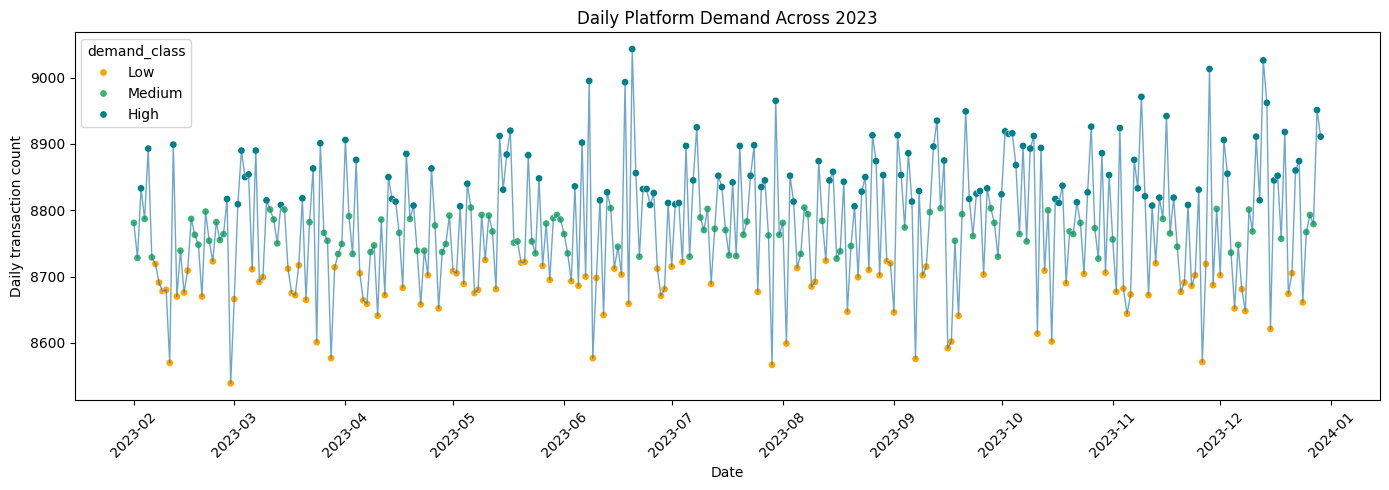

transaction_date,daily_transaction_count,daily_transaction_count_change,demand_class,day_of_week,holiday_status
2023-07-30T00:00:00.000Z,8965,398.0,High,Sunday,Non-holiday
2023-06-20T00:00:00.000Z,9043,384.0,High,Tuesday,Non-holiday
2023-02-12T00:00:00.000Z,8899,329.0,High,Sunday,Non-holiday
2023-03-25T00:00:00.000Z,8901,300.0,High,Saturday,Non-holiday
2023-06-08T00:00:00.000Z,8995,295.0,High,Thursday,Non-holiday
2023-10-11T00:00:00.000Z,8614,-298.0,Low,Wednesday,Non-holiday
2023-11-29T00:00:00.000Z,8687,-326.0,Low,Wednesday,Non-holiday
2023-06-19T00:00:00.000Z,8659,-334.0,Low,Monday,Public holiday
2023-12-15T00:00:00.000Z,8621,-341.0,Low,Friday,Non-holiday
2023-06-09T00:00:00.000Z,8577,-418.0,Low,Friday,Non-holiday


In [0]:
# -----------------------------------------------------------
# Chart 2 — Daily demand across time
# -----------------------------------------------------------

plt.figure(figsize=(14, 5))
plt.plot(
    storyDF["transaction_date"],
    storyDF["daily_transaction_count"],
    linewidth=1,
    alpha=0.65
)

sns.scatterplot(
    data=storyDF,
    x="transaction_date",
    y="daily_transaction_count",
    hue="demand_class",
    hue_order=classOrder,
    palette=demandPalette,
    s=28
)

plt.title("Daily Platform Demand Across 2023")
plt.xlabel("Date")
plt.ylabel("Daily transaction count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Show the largest increases and decreases as investigation anchors.
topMovementDaysPD = pd.concat(
    [
        storyDF.nlargest(5, "daily_transaction_count_change"),
        storyDF.nsmallest(5, "daily_transaction_count_change")
    ]
)[
    [
        "transaction_date",
        "daily_transaction_count",
        "daily_transaction_count_change",
        "demand_class",
        "day_of_week",
        "holiday_status"
    ]
].sort_values(
    "daily_transaction_count_change",
    ascending=False
)

display(topMovementDaysPD.round(2))

### Insight — Daily demand across 2023
- **Key finding:** Daily demand moves regularly between Low, Medium and High levels throughout the year, instead of staying at one level for a long period.
- **Interpretation:** This shows that platform demand changes from day to day, so we need to examine other factors that may help explain these changes.
- **Why it matters:** This supports looking at calendar, transaction, customer and market signals to understand when High demand happens

**One-line takeaway:**  
> “Demand changes throughout the year, so other signals are needed to explain when High-demand days occur.”


## 6.2 Calendar effects

Calendar variables are examined first because they are easy to interpret and are known before the demand date.

Three questions are tested:

1. **Overall public-holiday pattern:** Does the distribution of Low, Medium and High demand differ between public holidays and non-holidays?
2. **Specific holidays:** Which individual public holidays still experience High demand, and which fall into Low demand?
3. **Day of week:** Are some weekdays more likely to be High demand than others?

These charts show **association, not causation**. Holiday findings should also be interpreted cautiously because the number of public-holiday dates is much smaller than the number of non-holiday dates.

Holiday / non-holiday summary


holiday_status,days,average_daily_transactions,high_demand_days,high_demand_rate_pct
Non-holiday,316,8776.74,118,37.34
Public holiday,16,8748.5,6,37.5


Demand-class distribution by holiday status


Low,Medium,High
31.01,31.65,37.34
50.0,12.5,37.5


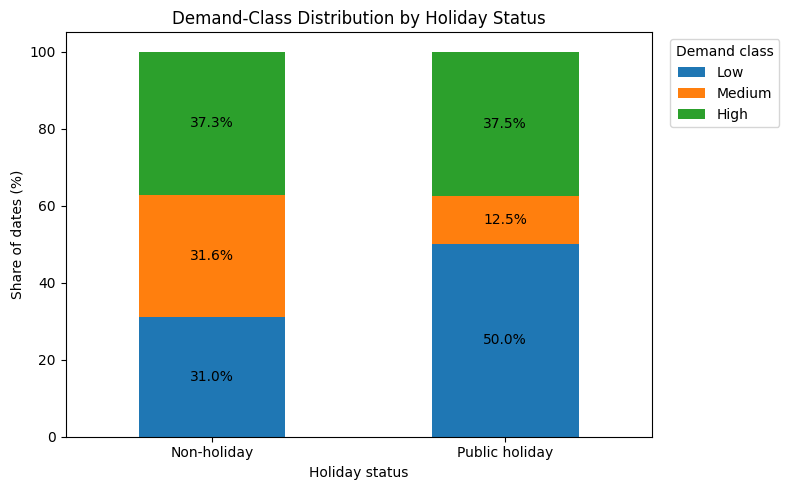

In [0]:
# -----------------------------------------------------------
# Calendar summary — holiday and weekday High-demand rates
# -----------------------------------------------------------

def calendar_high_demand_summary(data, group_col):
    result = (
        data
        .groupby(group_col, observed=False)
        .agg(
            days=("transaction_date", "count"),
            average_daily_transactions=("daily_transaction_count", "mean"),
            high_demand_days=("is_high_demand", "sum")
        )
        .reset_index()
    )

    result["high_demand_rate_pct"] = (
        result["high_demand_days"]
        / result["days"]
        * 100
    )

    return result


weekdayStorySummary = calendar_high_demand_summary(
    storyDF,
    "day_of_week"
)

holidayStorySummary = calendar_high_demand_summary(
    storyDF,
    "holiday_status"
)

print("Holiday / non-holiday summary")
display(holidayStorySummary.round(2))


# -----------------------------------------------------------
# Chart 3 — Demand-class distribution by holiday status
# -----------------------------------------------------------

holidayDemandDistribution = (
    storyDF
    .groupby(
        ["holiday_status", "demand_class"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
)

# Convert counts into percentages within each holiday group
holidayDemandPct = (
    holidayDemandDistribution
    .div(
        holidayDemandDistribution.sum(axis=1),
        axis=0
    )
    * 100
)

# Keep demand classes in logical order
holidayDemandPct = holidayDemandPct[
    ["Low", "Medium", "High"]
]

print("Demand-class distribution by holiday status")
display(holidayDemandPct.round(2))


ax = holidayDemandPct.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

for container in ax.containers:
    labels = [
        f"{value:.1f}%" if value >= 5 else ""
        for value in container.datavalues
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type="center"
    )

plt.title("Demand-Class Distribution by Holiday Status")
plt.xlabel("Holiday status")
plt.ylabel("Share of dates (%)")
plt.xticks(rotation=0)
plt.legend(
    title="Demand class",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


### Insight — Holiday status

- **Key finding:** Public holidays have more **Low-demand days (50.0%)** than non-holidays (**31.0%**).
- **However:** the share of **High-demand days is almost the same** for public holidays (**37.5%**) and non-holidays (**37.3%**).
- **Interpretation:** Public holidays seem to affect whether demand becomes **Low or Medium**, but they do not clearly reduce High demand.
- **Why it matters:** Since some public holidays are still High demand while others are Low demand, the next step is to examine the individual holidays more closely.

**One-line takeaway:**  
> “Public holidays are more often Low demand, so we next examine which types of public holidays contribute most to this pattern.”

Average daily transactions on non-holidays: 8,776.74

All public holidays


transaction_date,holiday_name,day_of_week,daily_transaction_count,demand_class,difference_from_nonholiday_avg
2023-07-20T00:00:00.000Z,Independence Day,Thursday,8897,High,120.26
2023-05-22T00:00:00.000Z,Ascension Day,Monday,8883,High,106.26
2023-03-20T00:00:00.000Z,Saint Joseph's Day,Monday,8818,High,41.26
2023-10-16T00:00:00.000Z,Columbus Day Holiday,Monday,8817,High,40.26
2023-07-03T00:00:00.000Z,Feast of Saint Peter and Saint Paul Holiday,Monday,8811,High,34.26
2023-08-21T00:00:00.000Z,Assumption of Mary Holiday,Monday,8806,High,29.26
2023-08-07T00:00:00.000Z,Battle of Boyacá Day,Monday,8804,Medium,27.26
2023-12-25T00:00:00.000Z,Christmas Day,Monday,8767,Medium,-9.74
2023-11-13T00:00:00.000Z,Independence of Cartagena,Monday,8720,Low,-56.74
2023-05-01T00:00:00.000Z,Labor Day,Monday,8708,Low,-68.74



High-demand public holidays


transaction_date,holiday_name,day_of_week,daily_transaction_count,demand_class,difference_from_nonholiday_avg
2023-07-20T00:00:00.000Z,Independence Day,Thursday,8897,High,120.26
2023-05-22T00:00:00.000Z,Ascension Day,Monday,8883,High,106.26
2023-03-20T00:00:00.000Z,Saint Joseph's Day,Monday,8818,High,41.26
2023-10-16T00:00:00.000Z,Columbus Day Holiday,Monday,8817,High,40.26
2023-07-03T00:00:00.000Z,Feast of Saint Peter and Saint Paul Holiday,Monday,8811,High,34.26
2023-08-21T00:00:00.000Z,Assumption of Mary Holiday,Monday,8806,High,29.26



Low-demand public holidays


transaction_date,holiday_name,day_of_week,daily_transaction_count,demand_class,difference_from_nonholiday_avg
2023-06-12T00:00:00.000Z,Corpus Christi Holiday,Monday,8642,Low,-134.74
2023-12-08T00:00:00.000Z,Feast of the Immaculate Conception,Friday,8648,Low,-128.74
2023-04-07T00:00:00.000Z,Good Friday,Friday,8659,Low,-117.74
2023-06-19T00:00:00.000Z,Sacred Heart,Monday,8659,Low,-117.74
2023-04-06T00:00:00.000Z,Maundy Thursday,Thursday,8664,Low,-112.74
2023-11-06T00:00:00.000Z,All Saints' Day Holiday,Monday,8673,Low,-103.74
2023-05-01T00:00:00.000Z,Labor Day,Monday,8708,Low,-68.74
2023-11-13T00:00:00.000Z,Independence of Cartagena,Monday,8720,Low,-56.74


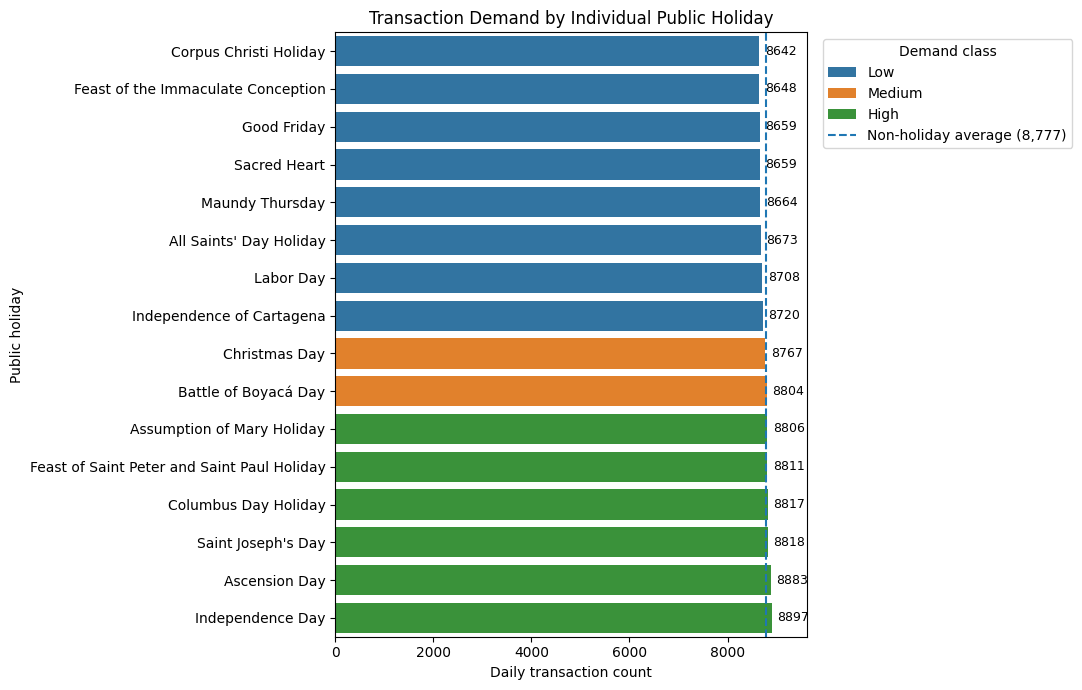

In [0]:
# -----------------------------------------------------------
# Chart 3A — Which specific public holidays are High or Low demand?
# -----------------------------------------------------------

# Convert holiday data to Pandas
holidayLookupPD = holidayPreparedDF.toPandas()

holidayLookupPD["holiday_date"] = pd.to_datetime(
    holidayLookupPD["holiday_date"]
).dt.normalize()

holidayDetailDF = storyDF.copy()

holidayDetailDF["transaction_date"] = pd.to_datetime(
    holidayDetailDF["transaction_date"]
).dt.normalize()

# Add holiday names to daily demand data
holidayDetailDF = holidayDetailDF.merge(
    holidayLookupPD,
    left_on="transaction_date",
    right_on="holiday_date",
    how="left"
)

# Keep only public holidays
publicHolidayDetail = holidayDetailDF[
    holidayDetailDF["is_public_holiday"].astype(int) == 1
][
    [
        "transaction_date",
        "holiday_name",
        "day_of_week",
        "daily_transaction_count",
        "demand_class"
    ]
].copy()


# -----------------------------------------------------------
# Average demand on normal non-holiday days
# -----------------------------------------------------------

nonHolidayAverage = storyDF.loc[
    storyDF["holiday_status"] == "Non-holiday",
    "daily_transaction_count"
].mean()

# Difference from normal non-holiday demand
publicHolidayDetail["difference_from_nonholiday_avg"] = (
    publicHolidayDetail["daily_transaction_count"]
    - nonHolidayAverage
)

print(f"Average daily transactions on non-holidays: {nonHolidayAverage:,.2f}")


# -----------------------------------------------------------
# Show public holidays
# -----------------------------------------------------------

print("\nAll public holidays")
display(
    publicHolidayDetail
    .sort_values("daily_transaction_count", ascending=False)
    .round(2)
)

print("\nHigh-demand public holidays")
display(
    publicHolidayDetail[
        publicHolidayDetail["demand_class"].astype(str) == "High"
    ]
    .sort_values("daily_transaction_count", ascending=False)
    .round(2)
)

print("\nLow-demand public holidays")
display(
    publicHolidayDetail[
        publicHolidayDetail["demand_class"].astype(str) == "Low"
    ]
    .sort_values("daily_transaction_count", ascending=True)
    .round(2)
)


# -----------------------------------------------------------
# Plot individual public holidays
# -----------------------------------------------------------

holidayPlotDF = publicHolidayDetail.sort_values(
    "daily_transaction_count",
    ascending=True
)

plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=holidayPlotDF,
    y="holiday_name",
    x="daily_transaction_count",
    hue="demand_class",
    dodge=False
)

# Add transaction count on each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=4,
        fontsize=9
    )

# Show average non-holiday demand
plt.axvline(
    nonHolidayAverage,
    linestyle="--",
    label=f"Non-holiday average ({nonHolidayAverage:,.0f})"
)

plt.title("Transaction Demand by Individual Public Holiday")
plt.xlabel("Daily transaction count")
plt.ylabel("Public holiday")

plt.xlim(
    0,
    holidayPlotDF["daily_transaction_count"].max() * 1.08
)

plt.legend(
    title="Demand class",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


### Insight — Specific public holidays

* **Key finding:** Public holidays do not have a consistent demand level, with individual holidays appearing across Low, Medium and High demand.
* **Lowest-demand holidays:** **Corpus Christi (8,642)**, **Feast of the Immaculate Conception (8,648)** and **Good Friday / Sacred Heart (8,659)** recorded some of the lowest transaction counts.
* **Highest-demand holidays:** **Independence Day (8,897)** and **Ascension Day (8,883)** recorded the highest transaction counts among public holidays.
* **Interpretation:** Independence Day stands out as a High-demand date, but other important holidays such as Good Friday recorded Low demand. This suggests that the importance of a holiday alone does not consistently explain transaction demand.
* **Why it matters:** Since public holidays can occur under different demand classes, the next step is to check whether **day of week provides a stronger and more consistent calendar pattern**.

**One-line takeaway:**

> “Even major public holidays can have either High or Low demand, so holiday status alone does not consistently explain transaction activity.”


day_of_week,days,average_daily_transactions,high_demand_days,high_demand_rate_pct
Monday,47,8760.49,14,29.79
Tuesday,47,8797.51,23,48.94
Wednesday,48,8768.35,15,31.25
Thursday,48,8782.75,18,37.5
Friday,48,8769.15,19,39.58
Saturday,47,8767.49,15,31.91
Sunday,47,8782.04,20,42.55


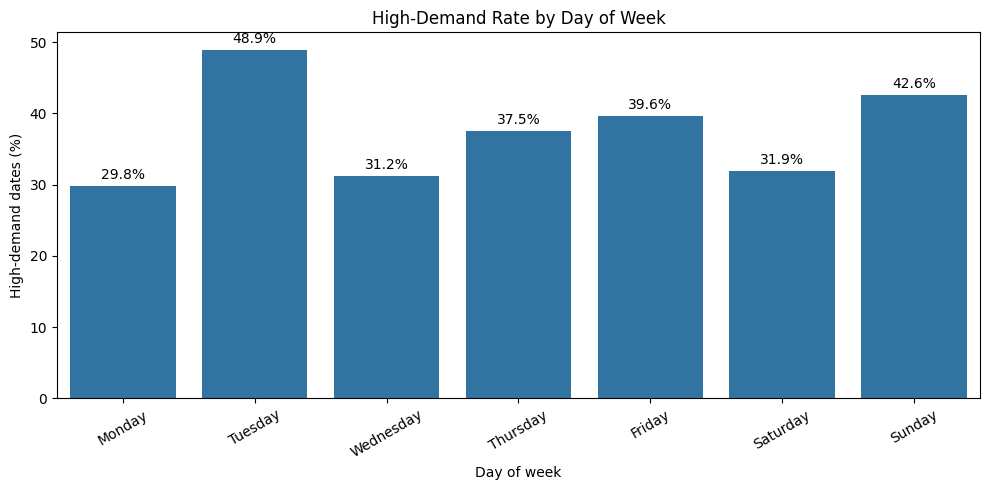

In [0]:
# -----------------------------------------------------------
# Chart 4 — High-demand rate by weekday
# -----------------------------------------------------------

weekdayStorySummary["day_of_week"] = pd.Categorical(
    weekdayStorySummary["day_of_week"],
    categories=dayOrder,
    ordered=True
)

weekdayStorySummary = weekdayStorySummary.sort_values(
    "day_of_week"
)

display(weekdayStorySummary.round(2))

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=weekdayStorySummary,
    x="day_of_week",
    y="high_demand_rate_pct",
    order=dayOrder
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.title("High-Demand Rate by Day of Week")
plt.xlabel("Day of week")
plt.ylabel("High-demand dates (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


### Insight — Day-of-week pattern

- **What it shows:** the percentage of each weekday that was classified as High demand.
- **Key finding:** **Tuesday has the highest High-demand rate at 48.94%**, while **Monday has the lowest at 29.79%**.
- **Interpretation:** weekday timing contains more information than the public-holiday flag, but no weekday guarantees High demand.
- **Why it matters:** calendar timing is useful as one signal, but other transaction and customer information is still needed.

**One-line takeaway:**  
> “Tuesday is more often High demand than Monday, but weekday alone is not enough to classify demand reliably.”


## 6.3 What is different on High-demand days?

Calendar timing provides some context, but it does not fully explain the demand level.

The next two charts describe what happens **on the day itself**:

1. Does the transaction-type mix change across demand levels?
2. Is High demand associated with more active customers or with the same customers making many more transactions?

These are **descriptive findings only**. Historical versions of the relevant variables are used for prediction.


demand_class,days,average_daily_transactions,average_total_transaction_value,transfer_share,payment_share,withdrawal_share,deposit_share,active_customers,transactions_per_active_customer,digital_engagement,product_adoption,power_customer_share,inactive_customer_share,cardholder_credit_utilization,average_trm
Low,106,8675.8868,3.48384685900943E10,0.4545,0.3072,0.1445,0.0938,4693.3396,1.8487,22.3062,2.0994,0.1001,0.2058,0.2888,4326.6192
Medium,102,8766.6471,3.48288335921569E10,0.4536,0.3068,0.1448,0.0948,4735.5588,1.8514,22.2782,2.0973,0.0996,0.207,0.2884,4345.3288
High,124,8867.6129,3.52209068322581E10,0.4535,0.3078,0.1442,0.0945,4785.1452,1.8533,22.2878,2.0976,0.0999,0.2067,0.2882,4217.6025


Daily transaction count vs total transaction value correlation: 0.02


demand_class,transaction_type,average_share,average_share_pct,share_label,transaction_rank_within_class,is_dominant_transaction_type
Low,Transfer,0.4545,45.45,45.45%,1,Dominant
Medium,Transfer,0.4536,45.36,45.36%,1,Dominant
High,Transfer,0.4535,45.35,45.35%,1,Dominant
Low,Payment,0.3072,30.72,30.72%,2,Other
Medium,Payment,0.3068,30.68,30.68%,2,Other
High,Payment,0.3078,30.78,30.78%,2,Other
Low,Withdrawal,0.1445,14.45,14.45%,3,Other
Medium,Withdrawal,0.1448,14.48,14.48%,3,Other
High,Withdrawal,0.1442,14.42,14.42%,3,Other
Low,Deposit,0.0938,9.38,9.38%,4,Other


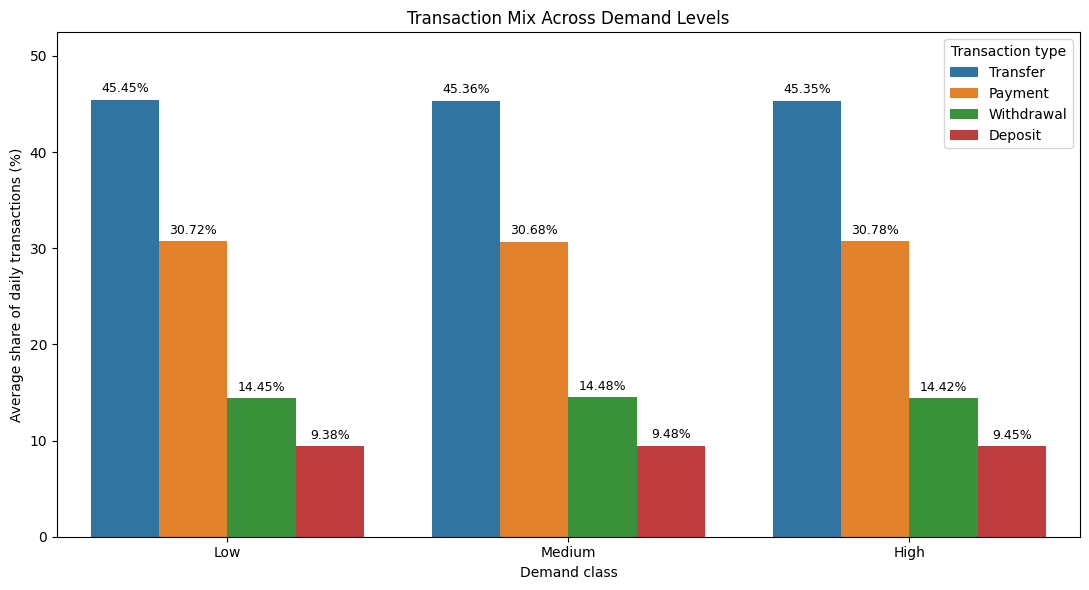

In [0]:
# Build a same-day profile for each demand class.
sameDayProfile = (
    storyDF
    .groupby(
        "demand_class",
        observed=False
    )
    .agg(
        days=("transaction_date", "count"),
        average_daily_transactions=(
            "daily_transaction_count",
            "mean"
        ),
        average_total_transaction_value=(
            "daily_total_transaction_amount",
            "mean"
        ),
        transfer_share=("transfer_share", "mean"),
        payment_share=("payment_share", "mean"),
        withdrawal_share=("withdrawal_share", "mean"),
        deposit_share=("deposit_share", "mean"),
        active_customers=("active_customer_count", "mean"),
        transactions_per_active_customer=(
            "transactions_per_active_customer",
            "mean"
        ),
        digital_engagement=(
            "avg_app_logins_frequency",
            "mean"
        ),
        product_adoption=(
            "avg_active_products",
            "mean"
        ),
        power_customer_share=(
            "power_customer_share",
            "mean"
        ),
        inactive_customer_share=(
            "inactive_customer_share",
            "mean"
        ),
        cardholder_credit_utilization=(
            "avg_credit_utilization_cardholders",
            "mean"
        ),
        average_trm=("exchange_rate", "mean")
    )
    .reindex(classOrder)
    .reset_index()
)

display(sameDayProfile.round(4))

countValueCorrelation = (
    storyDF["daily_transaction_count"]
    .corr(storyDF["daily_total_transaction_amount"])
)

print(
    "Daily transaction count vs total transaction value correlation:",
    round(countValueCorrelation, 3)
)

# Prepare transaction-type shares.
transactionMixPD = (
    sameDayProfile[
        [
            "demand_class",
            "transfer_share",
            "payment_share",
            "withdrawal_share",
            "deposit_share"
        ]
    ]
    .melt(
        id_vars="demand_class",
        var_name="transaction_type",
        value_name="average_share"
    )
)

transactionMixPD["transaction_type"] = (
    transactionMixPD["transaction_type"]
    .str.replace("_share", "", regex=False)
    .str.title()
)

transactionMixPD["transaction_rank_within_class"] = (
    transactionMixPD
    .groupby("demand_class", observed=False)["average_share"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

transactionMixPD["is_dominant_transaction_type"] = np.where(
    transactionMixPD["transaction_rank_within_class"] == 1,
    "Dominant",
    "Other"
)

# Add explicit percentage values for clearer comparison.
# The shares are close across demand classes, so percentage labels help
# reveal small differences that are difficult to judge from bar height alone.
transactionMixPD["average_share_pct"] = (
    transactionMixPD["average_share"] * 100
)

transactionMixPD["share_label"] = (
    transactionMixPD["average_share_pct"]
    .map(lambda value: f"{value:.2f}%")
)

display(
    transactionMixPD[
        [
            "demand_class",
            "transaction_type",
            "average_share",
            "average_share_pct",
            "share_label",
            "transaction_rank_within_class",
            "is_dominant_transaction_type"
        ]
    ].round({"average_share": 4, "average_share_pct": 2})
)

# -----------------------------------------------------------
# Chart 5 — Transaction mix across demand classes
# -----------------------------------------------------------
plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=transactionMixPD,
    x="demand_class",
    y="average_share_pct",
    hue="transaction_type",
    order=classOrder
)

# Show the exact percentage above every bar because the transaction mix
# is very similar across demand classes.
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=9
    )

plt.title("Transaction Mix Across Demand Levels")
plt.xlabel("Demand class")
plt.ylabel("Average share of daily transactions (%)")
plt.ylim(0, transactionMixPD["average_share_pct"].max() + 7)
plt.legend(title="Transaction type")
plt.tight_layout()
plt.show()

### Insight — Transaction mix

- **What it shows:** the average share of Transfer, Payment, Withdrawal and Deposit transactions within each demand class.
- **Key finding:** the transaction mix is very similar across Low, Medium and High demand. Transfer remains the largest type at about **45%**, followed by Payment at about **31%**.
- **Interpretation:** High-demand days are not caused by one transaction type suddenly dominating the platform.
- **Why it matters:** transaction mix may still add useful historical information, but it should be combined with other feature families rather than treated as the main driver.

**One-line takeaway:**  
> “The transaction mix barely changes across demand levels, so High demand is not explained by a major shift toward one transaction type.”


demand_class,active_customers,transactions_per_active_customer
Low,4693.3396,1.8487
Medium,4735.5588,1.8514
High,4785.1452,1.8533


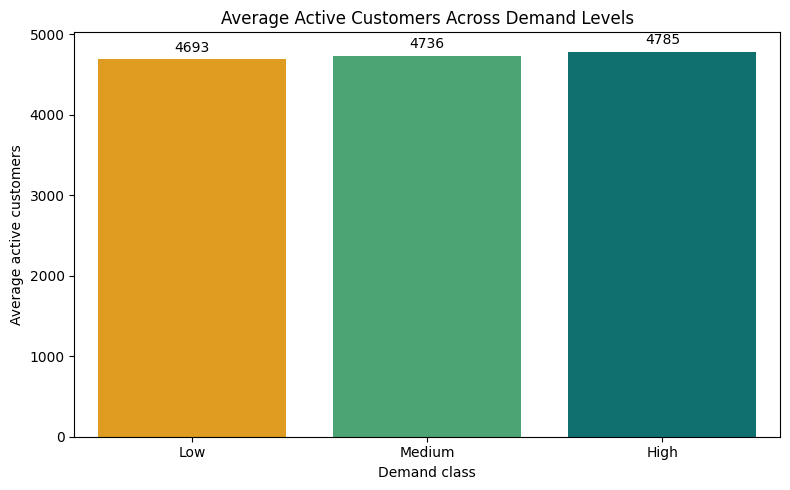

In [0]:
# -----------------------------------------------------------
# Chart 6 — Active customers across demand classes
# -----------------------------------------------------------

activityMechanismPD = (
    sameDayProfile[
        [
            "demand_class",
            "active_customers",
            "transactions_per_active_customer"
        ]
    ]
    .copy()
)

display(activityMechanismPD.round(4))

demandPalette = {
    "Low": "orange",
    "Medium": "mediumseagreen",
    "High": "teal"
}

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=activityMechanismPD,
    x="demand_class",
    y="active_customers",
    order=classOrder,
    hue="demand_class",
    palette=demandPalette,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Average Active Customers Across Demand Levels")
plt.xlabel("Demand class")
plt.ylabel("Average active customers")

plt.tight_layout()
plt.show()

### Insight — Active customers

- **What it shows:** the average number of active customers on Low, Medium and High demand days.
- **Key finding:** Low-demand days average about **4,693 active customers**, while High-demand days average about **4,785** — roughly **2% more**. Transactions per active customer change by only about **0.25%**.
- **Interpretation:** High demand is associated more with **more customers being active** than with each customer making many more transactions.
- **Why it matters:** historical active-customer levels are a sensible feature family to test in the predictive model.

**One-line takeaway:**  
> “High-demand days involve slightly more active customers, while transaction intensity per customer changes very little.”


## 6.4 Which clues were already visible before the demand day?

The previous charts explain what a demand day looks like. For prediction, the analysis now switches to the **historical features from Section 5**.

| Feature family | Examples of leakage-safe historical information |
|---|---|
| **Recent Demand** | previous-day count, 7-day / 28-day averages, same-weekday history, recent trend |
| **Transaction Behaviour / Mix** | previous 7-day median value and Transfer / Payment / Withdrawal shares |
| **Active-Customer Activity** | previous 7-day active-customer count and transaction intensity |
| **Engagement** | previous 7-day app-login frequency |
| **Product Adoption** | previous 7-day active products |
| **Customer Composition** | cardholder credit utilisation, Power-customer share, Inactive-customer share |
| **Market Context** | previous-day TRM and recent TRM change |

Calendar variables are already known in advance and were examined separately in Section 6.2.

For numerical historical features, correlation with future High demand is used only as an **exploratory measure of association**. It is not treated as causation, model importance or proof of the hypothesis.


In [0]:
# Define the historical signals to investigate.
historicalSignalSpecs = [
    # Recent demand
    ("Recent Demand", "Previous-day demand", "previous_day_transaction_count"),
    ("Recent Demand", "Previous 7-day average demand", "previous_7_day_avg_transaction_count"),
    ("Recent Demand", "Previous 28-day average demand", "previous_28_day_avg_transaction_count"),
    ("Recent Demand", "Previous 4 same-weekday average demand", "previous_4_same_weekday_avg_transaction_count"),
    ("Recent Demand", "7-day vs 28-day demand trend", "demand_trend_7_vs_28"),

    # Transaction composition
    ("Transaction Mix", "Previous 7-day Transfer share", "previous_7_day_avg_transfer_share"),
    ("Transaction Mix", "Previous 7-day Payment share", "previous_7_day_avg_payment_share"),
    ("Transaction Mix", "Previous 7-day Withdrawal share", "previous_7_day_avg_withdrawal_share"),

    # Active-customer activity
    ("Active-Customer Activity", "Previous 7-day active customers", "previous_7_day_avg_active_customer_count"),
    ("Active-Customer Activity", "Previous 7-day transaction intensity", "previous_7_day_avg_transactions_per_active_customer"),

    # Engagement
    ("Engagement", "Previous 7-day app-login frequency", "previous_7_day_avg_app_logins_frequency"),

    # Product adoption
    ("Product Adoption", "Previous 7-day active products", "previous_7_day_avg_active_products"),

    # Customer composition
    ("Customer Composition", "Previous 7-day cardholder credit utilisation", "previous_7_day_avg_credit_utilization_cardholders"),
    ("Customer Composition", "Previous 7-day Power-customer share", "previous_7_day_avg_power_customer_share"),
    ("Customer Composition", "Previous 7-day inactive-customer share", "previous_7_day_avg_inactive_customer_share"),

    # Market context
    ("Market Context", "Previous-day TRM", "previous_day_exchange_rate"),
    ("Market Context", "Recent TRM change", "previous_1_vs_7_day_exchange_rate_change")
]

featureFamilyOrder = [
    "Recent Demand",
    "Transaction Mix",
    "Active-Customer Activity",
    "Engagement",
    "Product Adoption",
    "Customer Composition",
    "Market Context"
]

historicalEvidenceRows = []

for signalGroup, signalName, columnName in historicalSignalSpecs:
    values = pd.to_numeric(
        storyDF[columnName],
        errors="coerce"
    )

    highCorrelation = values.corr(
        storyDF["is_high_demand"]
    )

    demandCorrelation = values.corr(
        storyDF["daily_transaction_count"]
    )

    classMeans = (
        storyDF
        .assign(_signal_value=values)
        .groupby(
            "demand_class",
            observed=False
        )["_signal_value"]
        .mean()
        .reindex(classOrder)
    )

    historicalEvidenceRows.append(
        {
            "signal_group": signalGroup,
            "signal": signalName,
            "column_name": columnName,
            "correlation_with_high_demand": (
                float(highCorrelation)
                if pd.notna(highCorrelation)
                else 0.0
            ),
            "correlation_with_daily_count": (
                float(demandCorrelation)
                if pd.notna(demandCorrelation)
                else 0.0
            ),
            "low_mean": float(classMeans.loc["Low"]) if pd.notna(classMeans.loc["Low"]) else np.nan,
            "medium_mean": float(classMeans.loc["Medium"]) if pd.notna(classMeans.loc["Medium"]) else np.nan,
            "high_mean": float(classMeans.loc["High"]) if pd.notna(classMeans.loc["High"]) else np.nan
        }
    )

historicalSignalEvidencePD = pd.DataFrame(
    historicalEvidenceRows
)

historicalSignalEvidencePD["absolute_high_demand_correlation"] = (
    historicalSignalEvidencePD[
        "correlation_with_high_demand"
    ].abs()
)

historicalSignalEvidencePD = (
    historicalSignalEvidencePD
    .sort_values(
        "absolute_high_demand_correlation",
        ascending=False
    )
    .reset_index(drop=True)
)

# Supporting table: all historical signals.
display(
    historicalSignalEvidencePD[
        [
            "signal_group",
            "signal",
            "correlation_with_high_demand",
            "correlation_with_daily_count",
            "low_mean",
            "medium_mean",
            "high_mean"
        ]
    ].round(4)
)

signal_group,signal,correlation_with_high_demand,correlation_with_daily_count,low_mean,medium_mean,high_mean
Market Context,Previous-day TRM,-0.1844,-0.1628,4329.7183,4345.7191,4221.1656
Transaction Mix,Previous 7-day Transfer share,-0.1494,-0.1388,0.4542,0.454,0.4534
Customer Composition,Previous 7-day cardholder credit utilisation,-0.1186,-0.1308,0.2885,0.2885,0.2883
Engagement,Previous 7-day app-login frequency,-0.1093,-0.1015,22.3011,22.2894,22.2828
Transaction Mix,Previous 7-day Payment share,0.1048,0.1268,0.3069,0.3073,0.3076
Recent Demand,Previous 4 same-weekday average demand,-0.0609,-0.0162,8775.4458,8774.0417,8769.3044
Recent Demand,Previous 28-day average demand,0.0609,0.0415,8772.0084,8772.8235,8774.5927
Recent Demand,Previous-day demand,-0.0592,-0.0553,8776.4906,8780.9804,8767.7016
Customer Composition,Previous 7-day Power-customer share,-0.053,-0.0855,0.1001,0.0997,0.0998
Market Context,Recent TRM change,-0.0252,-0.0096,-14.3404,-5.2971,-14.7076


### How to read the historical evidence

The historical-signal table and chart are **supporting evidence**, not the final hypothesis test.

- Correlation near **0** means little simple linear relationship with future High demand by itself.
- A **positive** value means higher historical values are associated with High demand more often.
- A **negative** value means higher historical values are associated with High demand less often.
- A weak correlation does not automatically make a feature useless because nonlinear models can combine several weak signals and interactions.
- Correlation does not prove causation or model importance.

To keep the chart readable, one representative numerical feature is shown from each feature family: the feature with the largest absolute simple correlation within that family.


Representative historical signal from each feature family


signal_group,signal,correlation_with_high_demand,correlation_with_daily_count
Recent Demand,Previous 4 same-weekday average demand,-0.0609,-0.0162
Transaction Mix,Previous 7-day Transfer share,-0.1494,-0.1388
Active-Customer Activity,Previous 7-day active customers,0.0146,-0.0051
Engagement,Previous 7-day app-login frequency,-0.1093,-0.1015
Product Adoption,Previous 7-day active products,0.0183,0.0293
Customer Composition,Previous 7-day cardholder credit utilisation,-0.1186,-0.1308
Market Context,Previous-day TRM,-0.1844,-0.1628


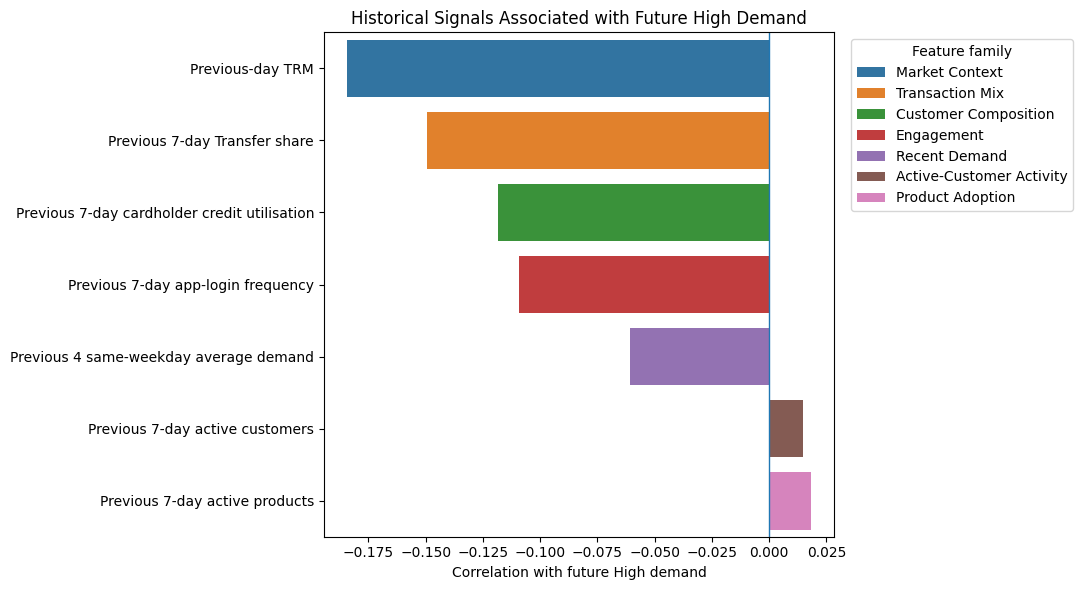

In [0]:
# Select one representative numerical signal from each feature family.
# Within each family, choose the variable with the largest absolute
# simple association with future High demand.

selectedRows = []

for signalGroup in featureFamilyOrder:
    groupRows = (
        historicalSignalEvidencePD[
            historicalSignalEvidencePD["signal_group"]
            == signalGroup
        ]
        .sort_values(
            "absolute_high_demand_correlation",
            ascending=False
        )
    )

    if len(groupRows) > 0:
        selectedRows.append(
            groupRows.iloc[0].to_dict()
        )

selectedHistoricalEvidencePD = pd.DataFrame(
    selectedRows
)

selectedHistoricalEvidencePD["family_order"] = (
    selectedHistoricalEvidencePD["signal_group"]
    .map(
        {
            group: index
            for index, group in enumerate(featureFamilyOrder)
        }
    )
)

selectedHistoricalEvidencePD = (
    selectedHistoricalEvidencePD
    .sort_values("family_order")
    .reset_index(drop=True)
)

print("Representative historical signal from each feature family")
display(
    selectedHistoricalEvidencePD[
        [
            "signal_group",
            "signal",
            "correlation_with_high_demand",
            "correlation_with_daily_count"
        ]
    ].round(4)
)

# -----------------------------------------------------------
# Chart 7 — Historical signals associated with future High demand
# -----------------------------------------------------------
plotEvidencePD = (
    selectedHistoricalEvidencePD
    .sort_values(
        "correlation_with_high_demand",
        ascending=True
    )
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=plotEvidencePD,
    y="signal",
    x="correlation_with_high_demand",
    hue="signal_group",
    dodge=False
)
plt.axvline(0, linewidth=1)
plt.title("Historical Signals Associated with Future High Demand")
plt.xlabel("Correlation with future High demand")
plt.ylabel("")
plt.legend(
    title="Feature family",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


### Insight — Historical signals before a High-demand day

* **What it shows:** The strongest leakage-safe historical signal from each feature family, selected using the largest absolute correlation with future High demand.
* **Key finding:** **Previous-day TRM** shows the strongest relationship with future High demand at about **-0.18**, followed by **previous 7-day Transfer share (-0.15)**, **cardholder credit utilisation (-0.12)** and **app-login frequency (-0.11)**.
* **Weaker signals:** The previous 4 same-weekday average demand has only a weak relationship at about **-0.06**, while **active customers** and **active products** are close to zero.
* **Interpretation:** Most relationships are weak to modest and several are negative, meaning higher historical values are associated with a lower likelihood of a future High-demand day. However, correlation alone does not imply causation.
* **Why it matters:** No single historical signal is strong enough to reliably identify High-demand days, supporting the use of a multivariate model that combines information across several feature families.

**One-line takeaway:**

> “Market context and transaction behaviour show the strongest individual associations with future High demand, but no single historical feature is strong enough on its own, so multiple signals are combined in the predictive models.”



## 6.5 What Section 6 tells us

The main findings from the exploration are:

1. **Demand classes are reasonably balanced**, allowing Low, Medium and High demand to be modelled without one class dominating the dataset.
2. **Demand changes throughout the year**, so assuming a constant level of daily transaction demand would not be appropriate.
3. **The overall public-holiday flag is weak for identifying High demand**, because the observed High-demand rate is similar between holidays and non-holidays.
4. **Individual public holidays behave differently.** Some important holidays, such as Independence Day, remain High demand, while others such as Good Friday are Low demand. Holiday status alone therefore does not consistently explain demand.
5. **Weekday timing appears more informative than holiday status**, with Tuesday showing the highest observed High-demand rate.
6. **Same-day transaction mix is relatively stable across demand classes**, suggesting that no single transaction type alone explains High demand.
7. **High-demand days have slightly more active customers**, while transactions per active customer change very little, suggesting that demand differences are driven more by the number of participating customers than by substantially heavier activity per customer.
8. **Historical signals are individually weak to modest.** Previous-day TRM shows the strongest simple association with future High demand at around **-0.18**, followed by previous 7-day Transfer share, cardholder credit utilisation and app-login frequency. Active-customer and product-adoption signals are much weaker.
9. **No single historical variable provides a clear rule for identifying future High demand**, supporting the use of a multivariate model that combines signals across several feature families.

Holiday-specific findings remain **exploratory** because only 16 public-holiday dates are available.

### Link to hypothesis

> **High-demand days can be detected using leakage-safe historical signals from recent transaction demand, calendar patterns, transaction behaviour and type composition, active-customer activity, engagement, product adoption, customer composition and market context. Combining these signals should provide useful classification of future Low, Medium and High demand, with particular attention to High-demand Recall and Macro F1.**

Section 6 therefore provides the **data story and modelling rationale**: individual signals provide some information, but none is sufficiently strong on its own. Section 8 tests whether combining these leakage-safe historical signals improves classification on later unseen dates.


%md
# 7. Modelling Objective and Model Training

## Modelling objective

The goal is to **train and compare classification models** that predict whether a future date will have **Low, Medium or High platform transaction demand**.

Only information available **before the prediction date** is used to avoid data leakage.

The modelling stage tests the following hypothesis:

> **High-demand days can be detected using leakage-safe historical signals from recent transaction demand, calendar patterns, transaction behaviour and type composition, active-customer activity, engagement, product adoption, customer composition and market context. Combining these signals should provide useful classification of future Low, Medium and High demand, with particular attention to High-demand Recall and Macro F1.**

Four classification models are trained and tested on later unseen dates to find out:

* which model performs best overall;
* how well each model predicts Low, Medium and High demand;
* how well each model detects actual High-demand dates; and
* whether the results support the hypothesis.

### Main evaluation metrics

The models are compared using:

* **Accuracy** — percentage of correct predictions;
* **Macro Precision** — average Precision across all three demand classes;
* **Macro Recall** — average Recall across all three demand classes;
* **Macro F1** — overall balance of Precision and Recall across all three classes;
* **High-demand Recall** — percentage of actual High-demand dates correctly detected.

Macro F1 is used as the main metric because Low, Medium and High demand are all important. It gives each class equal weight while balancing Precision and Recall.

Accuracy is not used alone because it can be **misleading if the model performs well on some classes but poorly on others**. It only shows the overall percentage of correct predictions and does not show how well Low, Medium and High demand are predicted separately.

### Modelling process

**(a)** encode the target;

**(b)** prepare the predictors and chronological train-test split;

**(c)** check predictor correlation;

**(d)** train four classification models;

**(e)** compare model performance;

**(f)** review the classification reports and confusion matrices;

**(g)** select the best model and assess whether the hypothesis is supported.

In [0]:
# Libraries for train/test splitting
from sklearn.model_selection import train_test_split

# Libraries for the four selected ML models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Model evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


### 7.1 Map targets into 0s, 1s and 2s

The demand labels are converted into numerical classes:

- **Low = 0**
- **Medium = 1**
- **High = 2**

The unique labels are checked before and after mapping so unexpected values cannot silently enter the model.


In [0]:
modellingDF = demandDF.copy()
print("Display first 10 rows of modelling dataframe")
print("=" * 20)
print("")
display(modellingDF.head(10))

# Check original label values
print(
    "Original labels:",
    modellingDF["demand_class"].astype(str).unique()
)

# Explicit target encoding
label_mapping = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

modellingDF["demand_class_encoded"] = (
    modellingDF["demand_class"]
    .astype(str)
    .map(label_mapping)
)

# Check for unexpected labels that were not mapped
if modellingDF["demand_class_encoded"].isna().any():
    raise ValueError(
        "Unexpected demand_class values found during label mapping."
    )

# Convert to integer
modellingDF["demand_class_encoded"] = (
    modellingDF["demand_class_encoded"].astype(int)
)

print("Label mapping: Low = 0, Medium = 1, High = 2")
print(
    "Encoded labels:",
    sorted(modellingDF["demand_class_encoded"].unique())
)

print("\nClass distribution:")
print(
    modellingDF["demand_class_encoded"]
    .value_counts()
    .sort_index()
)


Display first 10 rows of modelling dataframe



transaction_date,daily_transaction_count,daily_total_transaction_amount,daily_median_transaction_amount,day_of_week,is_public_holiday,previous_day_transaction_count,previous_7_day_transaction_count,previous_7_day_avg_transaction_count,previous_28_day_avg_transaction_count,previous_4_same_weekday_avg_transaction_count,demand_trend_7_vs_28,previous_7_day_avg_median_transaction_amount,previous_7_day_avg_transfer_share,previous_7_day_avg_payment_share,previous_7_day_avg_withdrawal_share,previous_day_exchange_rate,previous_1_vs_7_day_exchange_rate_change,previous_7_day_avg_active_customer_count,previous_7_day_avg_transactions_per_active_customer,previous_7_day_avg_app_logins_frequency,previous_7_day_avg_active_products,previous_7_day_avg_credit_utilization_cardholders,previous_7_day_avg_power_customer_share,previous_7_day_avg_inactive_customer_share,demand_class
2023-02-01T00:00:00.000Z,8781,3.394549435E10,1752750.0,Wednesday,0,8648,8808,8728.57142857143,8772.464285714286,8750.75,-43.89285714285688,1817057.142857143,0.4551430559067686,0.30460719951165743,0.1446419121648938,4632.2,86.26000000000022,4721.142857142857,1.8489706619954371,22.285617670939143,2.108523527187787,0.2881364067182405,0.09875432596098434,0.20412003085819472,Medium
2023-02-02T00:00:00.000Z,8728,2.817239555E10,1484300.0,Thursday,0,8781,8639,8724.714285714286,8772.42857142857,8741.75,-47.714285714284415,1813164.2857142857,0.45387958469878464,0.30487005626973535,0.145290179866989,4648.7,109.78999999999996,4726.571428571428,1.8460710574640082,22.319185183789262,2.103544348347877,0.28796260123602907,0.0991229101015643,0.2060667981832144,Medium
2023-02-03T00:00:00.000Z,8833,3.55481883E10,1890950.0,Friday,0,8728,8774,8737.42857142857,8772.5,8742.75,-35.07142857142935,1815985.7142857143,0.4532958728202168,0.30501902132664244,0.1451757538623861,4639.04,107.28999999999996,4724.571428571428,1.849571549438681,22.324424169641762,2.1029837022573585,0.28822434744859343,0.09938000170405238,0.20654902110586537,High
2023-02-04T00:00:00.000Z,8787,2.802173265E10,1490900.0,Saturday,0,8833,8825,8745.857142857143,8772.107142857143,8795.75,-26.25,1806250.0,0.4514147037341196,0.3064788230184213,0.14552478646538086,4584.44,35.9399999999996,4732.0,1.8484575695887993,22.30006574502488,2.1030786044904186,0.28827677225723125,0.0987175004541451,0.20742995373021905,Medium
2023-02-05T00:00:00.000Z,8893,2.88019298E10,1465000.0,Sunday,0,8787,8631,8740.42857142857,8771.17857142857,8766.5,-30.75,1730964.2857142857,0.45173074030575006,0.30557849552771155,0.14658698989612318,4669.74,121.23999999999978,4715.714285714285,1.853628075457154,22.242644816857172,2.102915828141822,0.2890536263800109,0.09985794674729871,0.20651823020364746,High
2023-02-06T00:00:00.000Z,8729,2.8141008E10,1477900.0,Monday,0,8893,8775,8777.857142857143,8773.857142857143,8777.25,4.0,1655842.857142857,0.4519090263126459,0.3063930878685796,0.14595599169852772,4669.74,121.23999999999978,4734.571428571428,1.8540789380900724,22.272112815143043,2.100477597079933,0.2898342130249573,0.0994597626714441,0.20762756174122618,Medium
2023-02-07T00:00:00.000Z,8719,2.81744185E10,1478250.0,Tuesday,0,8729,8648,8771.285714285714,8774.57142857143,8832.5,-3.285714285715585,1572492.857142857,0.45193918602661814,0.3061325516566172,0.14621112486235602,4669.74,37.539999999999964,4723.285714285715,1.8571196651691972,22.270895575416564,2.103025943912791,0.2892780470339179,0.09839717356829591,0.20818041479870636,Low
2023-02-08T00:00:00.000Z,8691,3.36715695E10,1771300.0,Wednesday,0,8719,8781,8781.42857142857,8765.107142857143,8750.5,16.321428571427532,1577150.0,0.45354900310545154,0.3049704117439241,0.14589175061928072,4776.25,127.55000000000018,4728.428571428572,1.85724717235796,22.331078211251015,2.0962618481406095,0.28864956005748693,0.09920357885262414,0.20838069744007673,Low
2023-02-09T00:00:00.000Z,8678,2.766021705E10,1485600.0,Thursday,0,8691,8728,8768.57142857143,8766.75,8742.25,1.821428571429351,1579800.0,0.453948947174606,0.3048776335703373,0.14622

Original labels: ['Medium' 'High' 'Low']
Label mapping: Low = 0, Medium = 1, High = 2
Encoded labels: [np.int64(0), np.int64(1), np.int64(2)]

Class distribution:
demand_class_encoded
0    106
1    102
2    124
Name: count, dtype: int64


### 7.2 Define features and target and split the data 70:30

`X` contains the leakage-safe predictors and `y` contains the encoded demand class.

`day_of_week` is **one-hot encoded** so the models can learn different weekday patterns without treating weekdays as a numerical order.

Because this is a future prediction problem, the split is chronological:

- earliest **70%** of dates → training;
- latest **30%** → testing.

`shuffle=False` preserves the time order and avoids future data entering the training period.


In [0]:
# Features
print("Predictor features used for X:")
display(predictorColumns)

X = modellingDF[predictorColumns].copy()

# Show original shape before dummy encoding
print("Shape before dummy encoding:", X.shape)

# Convert categorical day_of_week into model-ready dummy variables
# drop_first=False ensures all days of week are included, including Monday
X = pd.get_dummies(
    X,
    columns=["day_of_week"],
    drop_first=False,
    dtype=int
)

# Show shape after dummy encoding
print("Shape after dummy encoding:", X.shape)
print("Added columns:", [col for col in X.columns if col.startswith("day_of_week_")])

# Ensure all model inputs are numeric
X = X.apply(pd.to_numeric, errors="raise").astype(float)

# Target
y = modellingDF["demand_class_encoded"].copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

display(X.head())
display(y.head())

Predictor features used for X:


_1
day_of_week
is_public_holiday
previous_day_transaction_count
previous_7_day_transaction_count
previous_7_day_avg_transaction_count
previous_28_day_avg_transaction_count
previous_4_same_weekday_avg_transaction_count
demand_trend_7_vs_28
previous_7_day_avg_median_transaction_amount
previous_7_day_avg_transfer_share


Shape before dummy encoding: (332, 21)
Shape after dummy encoding: (332, 27)
Added columns: ['day_of_week_Monday', 'day_of_week_Tuesday', 'day_of_week_Wednesday', 'day_of_week_Thursday', 'day_of_week_Friday', 'day_of_week_Saturday', 'day_of_week_Sunday']
Feature dataset shape: (332, 27)
Target dataset shape: (332,)


is_public_holiday,previous_day_transaction_count,previous_7_day_transaction_count,previous_7_day_avg_transaction_count,previous_28_day_avg_transaction_count,previous_4_same_weekday_avg_transaction_count,demand_trend_7_vs_28,previous_7_day_avg_median_transaction_amount,previous_7_day_avg_transfer_share,previous_7_day_avg_payment_share,previous_7_day_avg_withdrawal_share,previous_day_exchange_rate,previous_1_vs_7_day_exchange_rate_change,previous_7_day_avg_active_customer_count,previous_7_day_avg_transactions_per_active_customer,previous_7_day_avg_app_logins_frequency,previous_7_day_avg_active_products,previous_7_day_avg_credit_utilization_cardholders,previous_7_day_avg_power_customer_share,previous_7_day_avg_inactive_customer_share,day_of_week_Monday,day_of_week_Tuesday,day_of_week_Wednesday,day_of_week_Thursday,day_of_week_Friday,day_of_week_Saturday,day_of_week_Sunday
0.0,8648.0,8808.0,8728.57142857143,8772.464285714286,8750.75,-43.89285714285688,1817057.142857143,0.4551430559067686,0.30460719951165743,0.1446419121648938,4632.2,86.26000000000022,4721.142857142857,1.8489706619954371,22.285617670939143,2.108523527187787,0.2881364067182405,0.09875432596098434,0.20412003085819472,0.0,0.0,1.0,0.0,0.0,0.0,0.0
0.0,8781.0,8639.0,8724.714285714286,8772.42857142857,8741.75,-47.714285714284415,1813164.2857142857,0.45387958469878464,0.30487005626973535,0.145290179866989,4648.7,109.78999999999996,4726.571428571428,1.8460710574640082,22.319185183789262,2.103544348347877,0.28796260123602907,0.0991229101015643,0.2060667981832144,0.0,0.0,0.0,1.0,0.0,0.0,0.0
0.0,8728.0,8774.0,8737.42857142857,8772.5,8742.75,-35.07142857142935,1815985.7142857143,0.4532958728202168,0.30501902132664244,0.1451757538623861,4639.04,107.28999999999996,4724.571428571428,1.849571549438681,22.324424169641762,2.1029837022573585,0.28822434744859343,0.09938000170405238,0.20654902110586537,0.0,0.0,0.0,0.0,1.0,0.0,0.0
0.0,8833.0,8825.0,8745.857142857143,8772.107142857143,8795.75,-26.25,1806250.0,0.4514147037341196,0.3064788230184213,0.14552478646538086,4584.44,35.9399999999996,4732.0,1.8484575695887993,22.30006574502488,2.1030786044904186,0.28827677225723125,0.0987175004541451,0.20742995373021905,0.0,0.0,0.0,0.0,0.0,1.0,0.0
0.0,8787.0,8631.0,8740.42857142857,8771.17857142857,8766.5,-30.75,1730964.2857142857,0.45173074030575006,0.30557849552771155,0.14658698989612318,4669.74,121.23999999999978,4715.714285714285,1.853628075457154,22.242644816857172,2.102915828141822,0.2890536263800109,0.09985794674729871,0.20651823020364746,0.0,0.0,0.0,0.0,0.0,0.0,1.0


0    1
1    1
2    2
3    1
4    2
Name: demand_class_encoded, dtype: int64

In [0]:
# Chronological 70:30 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    shuffle=False
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nOriginal Dataset Class Distribution:")
print(y.value_counts().sort_index())

print("\nTraining Set Class Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Set Class Distribution:")
print(y_test.value_counts().sort_index())


Training rows: 232
Testing rows: 100

Original Dataset Class Distribution:
demand_class_encoded
0    106
1    102
2    124
Name: count, dtype: int64

Training Set Class Distribution:
demand_class_encoded
0    78
1    77
2    77
Name: count, dtype: int64

Testing Set Class Distribution:
demand_class_encoded
0    28
1    25
2    47
Name: count, dtype: int64



**Why a 70:30 split?**  
A 70:30 split uses the first 70% of dates for training and the last 30% for testing. This provides enough historical data for training while keeping a later set of unseen dates to evaluate future prediction performance.

### 7.3 Predictor correlation and multicollinearity screening

Before training the models, **Pearson correlation** is used to check whether any numerical predictors are strongly related to each other.

This helps identify possible **multicollinearity**, where two predictors may be providing very similar information to the model.

- Predictor pairs with **|correlation| ≥ 0.80** are flagged for review.
- Only the **training data** is used so the test data does not influence model preparation.
- `day_of_week` dummy variables are excluded because they represent categories rather than continuous numerical measures.
- A high correlation does **not automatically mean a feature is removed**. The correlated predictors are reviewed first before deciding whether they should be kept.

This check helps make sure the predictor set does not contain too many strongly overlapping numerical features before model training.

Numerical modelling-feature correlation matrix


is_public_holiday,previous_day_transaction_count,previous_7_day_transaction_count,previous_7_day_avg_transaction_count,previous_28_day_avg_transaction_count,previous_4_same_weekday_avg_transaction_count,demand_trend_7_vs_28,previous_7_day_avg_median_transaction_amount,previous_7_day_avg_transfer_share,previous_7_day_avg_payment_share,previous_7_day_avg_withdrawal_share,previous_day_exchange_rate,previous_1_vs_7_day_exchange_rate_change,previous_7_day_avg_active_customer_count,previous_7_day_avg_transactions_per_active_customer,previous_7_day_avg_app_logins_frequency,previous_7_day_avg_active_products,previous_7_day_avg_credit_utilization_cardholders,previous_7_day_avg_power_customer_share,previous_7_day_avg_inactive_customer_share
1.0,-0.003,-0.035,-0.0,0.003,-0.112,-0.002,0.139,-0.014,0.007,0.02,-0.028,0.053,0.071,-0.093,0.117,-0.119,-0.081,0.069,0.022
-0.003,1.0,-0.053,0.337,0.19,0.016,0.281,0.059,-0.134,0.137,-0.037,-0.149,-0.095,0.224,0.03,-0.129,0.031,-0.093,-0.088,0.014
-0.035,-0.053,1.0,0.324,0.185,0.483,0.269,0.032,-0.007,0.055,-0.047,-0.187,-0.021,0.234,0.006,0.029,-0.013,0.06,0.085,0.063
-0.0,0.337,0.324,1.0,0.565,0.221,0.833,0.134,-0.132,0.223,-0.146,-0.504,-0.168,0.642,0.12,-0.151,-0.012,-0.052,0.079,0.124
0.003,0.19,0.185,0.565,1.0,0.398,0.014,0.269,-0.209,0.315,-0.175,-0.826,-0.105,0.186,0.295,0.025,0.171,0.021,-0.136,0.046
-0.112,0.016,0.483,0.221,0.398,1.0,0.0,0.125,-0.092,0.11,-0.045,-0.322,0.001,0.058,0.134,0.035,0.026,-0.007,-0.062,0.027
-0.002,0.281,0.269,0.833,0.014,0.0,1.0,-0.018,-0.019,0.059,-0.059,-0.057,-0.133,0.653,-0.052,-0.2,-0.128,-0.077,0.186,0.119
0.139,0.059,0.032,0.134,0.269,0.125,-0.018,1.0,-0.159,0.023,0.115,-0.439,0.151,-0.051,0.194,-0.046,-0.112,-0.219,-0.132,0.155
-0.014,-0.134,-0.007,-0.132,-0.209,-0.092,-0.019,-0.159,1.0,-0.713,-0.34,0.155,-0.022,-0.11,0.019,-0.061,0.023,0.345,0.076,-0.059
0.007,0.137,0.055,0.223,0.315,0.11,0.059,0.023,-0.713,1.0,-0.215,-0.229,-0.085,0.17,-0.011,0.031,-0.041,-0.115,0.02,-0.055


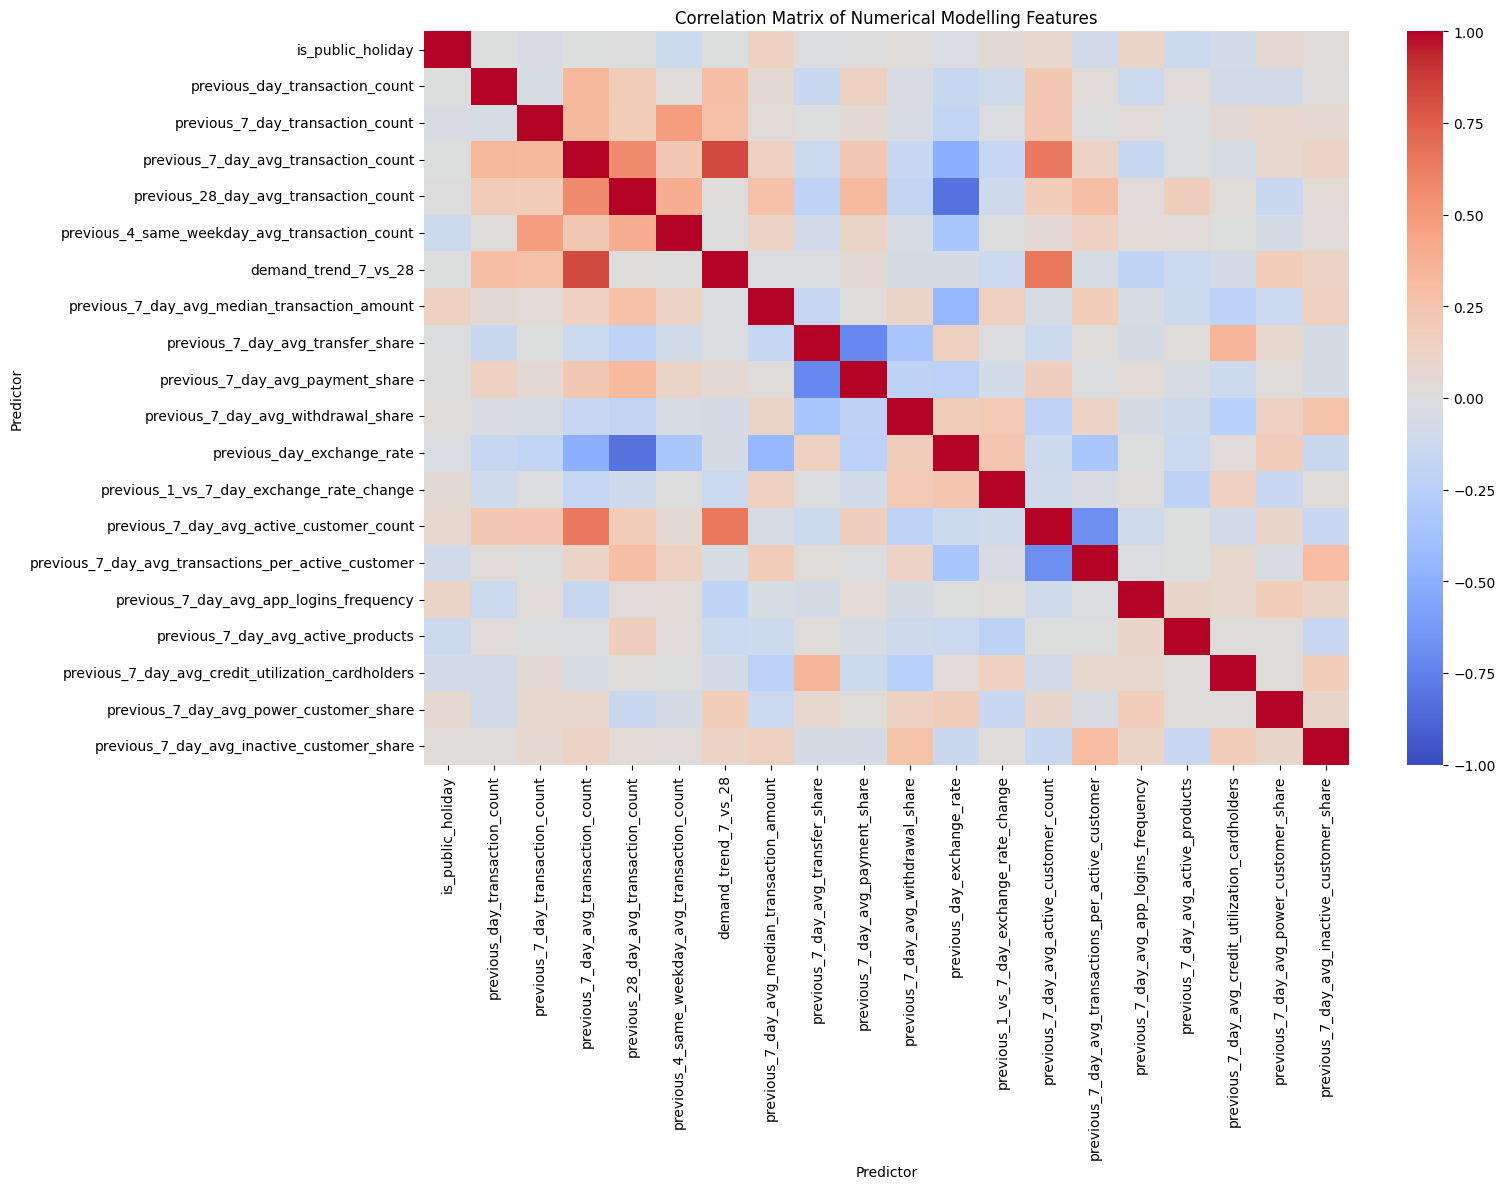

Strongest predictor correlations


feature_1,feature_2,correlation,absolute_correlation
previous_7_day_avg_transaction_count,demand_trend_7_vs_28,0.833,0.833
previous_28_day_avg_transaction_count,previous_day_exchange_rate,-0.826,0.826
previous_7_day_avg_transfer_share,previous_7_day_avg_payment_share,-0.713,0.713
previous_7_day_avg_active_customer_count,previous_7_day_avg_transactions_per_active_customer,-0.684,0.684
demand_trend_7_vs_28,previous_7_day_avg_active_customer_count,0.653,0.653
previous_7_day_avg_transaction_count,previous_7_day_avg_active_customer_count,0.642,0.642
previous_7_day_avg_transaction_count,previous_28_day_avg_transaction_count,0.565,0.565
previous_7_day_avg_transaction_count,previous_day_exchange_rate,-0.504,0.504
previous_7_day_transaction_count,previous_4_same_weekday_avg_transaction_count,0.483,0.483
previous_7_day_avg_median_transaction_amount,previous_day_exchange_rate,-0.439,0.439


Predictor pairs with |correlation| >= 0.80: 2


feature_1,feature_2,correlation,absolute_correlation
previous_7_day_avg_transaction_count,demand_trend_7_vs_28,0.833,0.833
previous_28_day_avg_transaction_count,previous_day_exchange_rate,-0.826,0.826


In [0]:
# -----------------------------------------------------------
# Predictor correlation / multicollinearity screening
# -----------------------------------------------------------

# Use training data only
correlationFeatureColumns = [
    column
    for column in X_train.columns
    if not column.startswith("day_of_week_")
]

# Create correlation matrix
modellingCorrelationMatrix = (
    X_train[correlationFeatureColumns]
    .corr(method="pearson")
)

print("Numerical modelling-feature correlation matrix")
display(modellingCorrelationMatrix.round(3))


# -----------------------------------------------------------
# Correlation heatmap
# -----------------------------------------------------------

plt.figure(figsize=(16, 12))

sns.heatmap(
    modellingCorrelationMatrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Numerical Modelling Features")
plt.xlabel("Predictor")
plt.ylabel("Predictor")
plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


# -----------------------------------------------------------
# Find strongest predictor correlations
# -----------------------------------------------------------

upperTriangleMask = np.triu(
    np.ones(modellingCorrelationMatrix.shape),
    k=1
).astype(bool)

upperTriangle = modellingCorrelationMatrix.where(
    upperTriangleMask
)

correlationPairs = (
    upperTriangle
    .stack()
    .reset_index()
)

correlationPairs.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

correlationPairs["absolute_correlation"] = (
    correlationPairs["correlation"].abs()
)

correlationPairs = (
    correlationPairs
    .sort_values(
        "absolute_correlation",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Strongest predictor correlations")

display(
    correlationPairs
    .head(15)
    .round(3)
)


# -----------------------------------------------------------
# Flag correlations >= 0.80
# -----------------------------------------------------------

highCorrelationThreshold = 0.80

highCorrelationPairs = correlationPairs[
    correlationPairs["absolute_correlation"]
    >= highCorrelationThreshold
]

print(
    f"Predictor pairs with |correlation| >= "
    f"{highCorrelationThreshold:.2f}: "
    f"{len(highCorrelationPairs)}"
)

display(highCorrelationPairs.round(3))

### Multicollinearity result

- Only **two predictor pairs** exceeded the **|correlation| ≥ 0.80** threshold:
  - Previous 7-day average transaction count and demand trend: **0.833**
  - Previous 28-day average transaction count and previous-day exchange rate: **-0.826**
- High correlation is therefore **limited rather than widespread**.
- The features are retained because Logistic Regression uses **L2 regularisation** (shrinks weights towards zero), while the tree-based models are less sensitive to correlated predictors.
- Their usefulness will be evaluated through model performance on unseen dates.

**One-line takeaway:**  
> “Only two predictor pairs show high correlation, so the features are retained for model comparison.”

### 7.4 Model selection rationale and training

Four classification models are compared using the same leakage-safe feature set:

- **Multinomial Logistic Regression** — provides a simple linear comparison model;
- **Random Forest** — can capture nonlinear relationships and interactions between several historical signals;
- **Gradient Boosting** — builds trees step-by-step to improve earlier prediction errors;
- **AdaBoost** — gives more attention to observations that were previously misclassified.

This allows a comparison between a **linear model, bagging model and two boosting approaches**, which is useful because the earlier exploration showed that no single historical signal clearly explains future demand.

All models use the same training period and are evaluated on the same later unseen test period for a fair comparison.

In [0]:
scaler = StandardScaler()

# Fit preprocessing on training data only
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# 1. Multinomial Logistic Regression
lr = LogisticRegression(
    penalty="l2",
    solver="lbfgs",
    C=0.5,
    max_iter=2000,
    random_state=42
)


# 2. Random Forest
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=4,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42
)


# 3. Gradient Boosting
gb = GradientBoostingClassifier(
    n_estimators=120,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=4,
    subsample=0.85,
    random_state=42
)


# 4. AdaBoost
adaboost = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.10,
    random_state=42
)


# Train all four models
lr.fit(X_train_scaled, y_train)
rf.fit(X_train_scaled, y_train)
gb.fit(X_train_scaled, y_train)
adaboost.fit(X_train_scaled, y_train)

print("All four models trained successfully.")

All four models trained successfully.


`StandardScaler` is fitted using the **training data only** to avoid data leakage. It standardises predictors to a similar scale, which is important for **Logistic Regression** because feature magnitude can affect its coefficients. Tree-based models are much less sensitive to differences in feature scale.

# 8. Model Evaluation and Hypothesis Assessment

All four classification models are evaluated on the **same later chronological test set** to ensure a fair comparison on unseen future dates.

The evaluation focuses on:

- **Accuracy** — overall proportion of correctly classified dates;
- **Macro Precision** — average precision across Low, Medium and High demand;
- **Macro Recall** — average recall across the three demand classes;
- **Macro F1** — balanced classification performance across all three classes; and
- **High-demand Recall** — proportion of actual High-demand dates correctly detected.

**Macro F1** is used as the main measure of balanced overall performance, while **High-demand Recall** is examined separately because identifying future High-demand dates is operationally important.

The results are then used to identify the strongest model and assess whether the modelling hypothesis is supported.

## 8.1 Model Comparison

The four trained models are compared using the main evaluation metrics.

This gives an overall view of model performance across Low, Medium and High demand, while also showing how well each model detects actual High-demand dates.

In [0]:
models_dict = {
    "Multinomial Logistic Regression": lr,
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "AdaBoost": adaboost
}

acc_scores = {}
macro_precision_scores = {}
macro_recall_scores = {}
macro_f1_scores = {}
high_recall_scores = {}

predictions = {}


# Evaluate all four trained models
for name, model in models_dict.items():

    preds = model.predict(X_test_scaled)
    predictions[name] = preds

    acc_scores[name] = accuracy_score(
        y_test,
        preds
    )

    macro_precision_scores[name] = precision_score(
        y_test,
        preds,
        average="macro",
        zero_division=0
    )

    macro_recall_scores[name] = recall_score(
        y_test,
        preds,
        average="macro",
        zero_division=0
    )

    macro_f1_scores[name] = f1_score(
        y_test,
        preds,
        average="macro",
        zero_division=0
    )

    high_recall_scores[name] = recall_score(
        y_test,
        preds,
        labels=[2],
        average=None,
        zero_division=0
    )[0]


# Create model comparison table
comparisonDF = pd.DataFrame({
    "Model": list(models_dict.keys()),

    "Accuracy": [
        acc_scores[name]
        for name in models_dict
    ],

    "Macro Precision": [
        macro_precision_scores[name]
        for name in models_dict
    ],

    "Macro Recall": [
        macro_recall_scores[name]
        for name in models_dict
    ],

    "Macro F1": [
        macro_f1_scores[name]
        for name in models_dict
    ],

    "High-demand Recall": [
        high_recall_scores[name]
        for name in models_dict
    ]
})


# Rank models by Macro F1
comparisonDF = (
    comparisonDF
    .sort_values(
        "Macro F1",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    comparisonDF.round(4)
)

Model,Accuracy,Macro Precision,Macro Recall,Macro F1,High-demand Recall
Random Forest,0.45,0.4384,0.4283,0.4302,0.5319
Gradient Boosting,0.4,0.3936,0.3866,0.3861,0.4468
AdaBoost,0.43,0.3827,0.3829,0.3754,0.5957
Multinomial Logistic Regression,0.34,0.3292,0.3324,0.3245,0.383


### Overall comparison

- **Random Forest** performed best overall, with the highest **Accuracy of 45.00%** and **Macro F1 of 43.02%**.
- **Gradient Boosting** had the second-highest Macro F1 of **38.61%**.
- **AdaBoost** achieved the highest **High-demand Recall of 59.57%**, detecting **28 of 47 High-demand dates**.
- **Multinomial Logistic Regression** performed weakest overall, with **34.00% Accuracy** and **32.45% Macro F1**.

Overall, **Random Forest gives the best balance across Low, Medium and High demand**, while **AdaBoost detects more actual High-demand dates**.

## 8.2 Classification Reports

The classification reports show **Precision, Recall and F1 Score for Low, Medium and High demand**, together with overall Accuracy and macro averages.

This helps show which demand classes each model predicts well or poorly.

In [0]:
# Classification Reports

for name in models_dict:

    print(
        f"================ {name} ================"
    )

    print(
        classification_report(
            y_test,
            predictions[name],
            labels=[0, 1, 2],
            target_names=[
                "Low",
                "Medium",
                "High"
            ],
            zero_division=0
        )
    )

    print(
        f"{name} Accuracy Score: "
        f"{acc_scores[name]:.4f}\n"
    )

================ Multinomial Logistic Regression ================
              precision    recall  f1-score   support

         Low       0.23      0.21      0.22        28
      Medium       0.27      0.40      0.32        25
        High       0.49      0.38      0.43        47

    accuracy                           0.34       100
   macro avg       0.33      0.33      0.32       100
weighted avg       0.36      0.34      0.34       100

Multinomial Logistic Regression Accuracy Score: 0.3400

================ Random Forest ================
              precision    recall  f1-score   support

         Low       0.48      0.39      0.43        28
      Medium       0.28      0.36      0.32        25
        High       0.56      0.53      0.54        47

    accuracy                           0.45       100
   macro avg       0.44      0.43      0.43       100
weighted avg       0.47      0.45      0.46       100

Random Forest Accuracy Score: 0.4500

================ Gradient Boos

### Classification-report findings

- **Random Forest** gives the best overall balance across the three demand classes.
- **AdaBoost** achieved the highest High-demand Recall of **0.60**, but its Medium-demand Recall was only **0.16**.
- **Gradient Boosting** was more balanced than AdaBoost, but still performed below Random Forest.
- **Multinomial Logistic Regression** had the weakest overall performance.

Overall, **Medium demand is the hardest class to predict**, while the models perform better at detecting High demand.

## 8.3 Confusion Matrices

The confusion matrices show the number of dates belonging to each **actual and predicted demand class**.

- Diagonal values represent correctly classified dates.
- Off-diagonal values represent misclassified dates.

This helps show where each model makes prediction errors, especially when actual High-demand dates are predicted as Medium or Low demand.

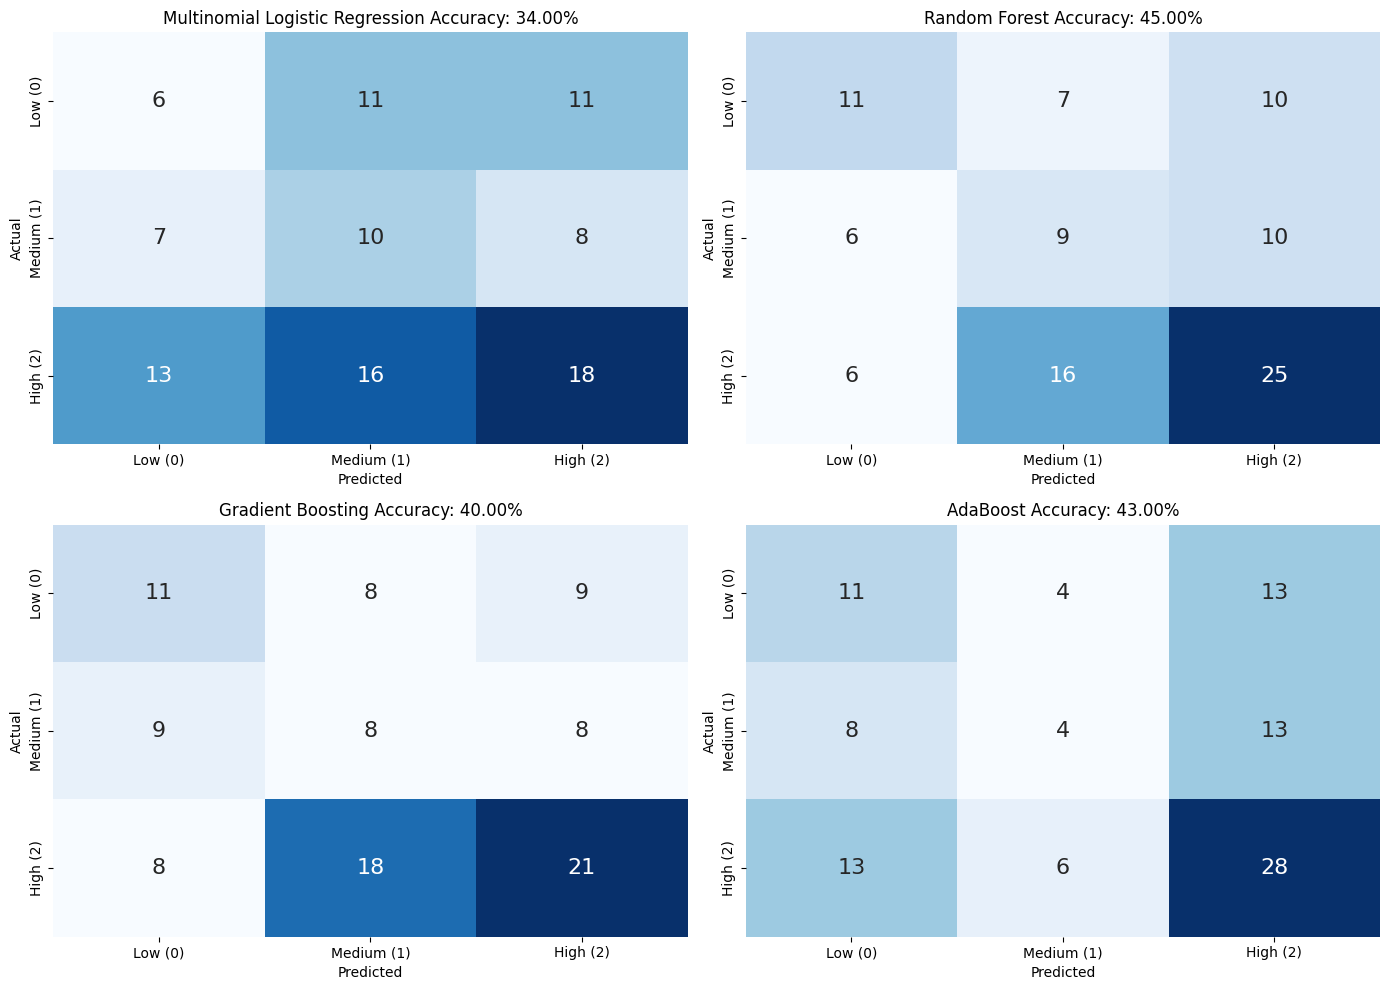

In [0]:
# Confusion Matrix

# Compute confusion matrices using the exact model predictions
lr_cm = confusion_matrix(
    y_test,
    predictions["Multinomial Logistic Regression"],
    labels=[0, 1, 2]
)

rf_cm = confusion_matrix(
    y_test,
    predictions["Random Forest"],
    labels=[0, 1, 2]
)

gb_cm = confusion_matrix(
    y_test,
    predictions["Gradient Boosting"],
    labels=[0, 1, 2]
)

adaboost_cm = confusion_matrix(
    y_test,
    predictions["AdaBoost"],
    labels=[0, 1, 2]
)


# Create a 2x2 subplot grid
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

class_labels = [
    "Low (0)",
    "Medium (1)",
    "High (2)"
]


# 1. Multinomial Logistic Regression
sns.heatmap(
    lr_cm,
    annot=True,
    annot_kws={"size": 16},
    fmt="g",
    cmap="Blues",
    cbar=False,
    xticklabels=class_labels,
    yticklabels=class_labels,
    ax=axes[0][0]
)

axes[0][0].set_title(
    f"Multinomial Logistic Regression Accuracy: "
    f"{acc_scores['Multinomial Logistic Regression']:.2%}"
)

axes[0][0].set_xlabel("Predicted")
axes[0][0].set_ylabel("Actual")


# 2. Random Forest
sns.heatmap(
    rf_cm,
    annot=True,
    annot_kws={"size": 16},
    fmt="g",
    cmap="Blues",
    cbar=False,
    xticklabels=class_labels,
    yticklabels=class_labels,
    ax=axes[0][1]
)

axes[0][1].set_title(
    f"Random Forest Accuracy: "
    f"{acc_scores['Random Forest']:.2%}"
)

axes[0][1].set_xlabel("Predicted")
axes[0][1].set_ylabel("Actual")


# 3. Gradient Boosting
sns.heatmap(
    gb_cm,
    annot=True,
    annot_kws={"size": 16},
    fmt="g",
    cmap="Blues",
    cbar=False,
    xticklabels=class_labels,
    yticklabels=class_labels,
    ax=axes[1][0]
)

axes[1][0].set_title(
    f"Gradient Boosting Accuracy: "
    f"{acc_scores['Gradient Boosting']:.2%}"
)

axes[1][0].set_xlabel("Predicted")
axes[1][0].set_ylabel("Actual")


# 4. AdaBoost
sns.heatmap(
    adaboost_cm,
    annot=True,
    annot_kws={"size": 16},
    fmt="g",
    cmap="Blues",
    cbar=False,
    xticklabels=class_labels,
    yticklabels=class_labels,
    ax=axes[1][1]
)

axes[1][1].set_title(
    f"AdaBoost Accuracy: "
    f"{acc_scores['AdaBoost']:.2%}"
)

axes[1][1].set_xlabel("Predicted")
axes[1][1].set_ylabel("Actual")


plt.tight_layout()
plt.show()

### Confusion-matrix findings

- **Random Forest** correctly predicted **11 Low, 9 Medium and 25 High-demand dates**, giving the best overall balance.
- **AdaBoost** detected the most High-demand dates, correctly predicting **28 of 47**, but only correctly predicted **4 of 25 Medium-demand dates**.
- **Gradient Boosting** correctly detected **21 High-demand dates**.
- **Multinomial Logistic Regression** detected only **18 High-demand dates** and had the lowest overall Accuracy.

This again shows that **Random Forest is more balanced**, while **AdaBoost is better at detecting more High-demand dates**.

## 8.4 Result Interpretation and Hypothesis Assessment

**Random Forest** achieved the best balanced performance with **45.00% Accuracy** and **43.02% Macro F1**, making it the strongest model across Low, Medium and High demand.

**AdaBoost** achieved the highest **High-demand Recall of 59.57%**, meaning it detected more actual High-demand dates. However, its weaker performance on Medium demand made it less balanced than Random Forest.

The limited model performance is likely related to:

- only **332 daily observations** being available for modelling;
- most historical predictors having **weak relationships with future demand**;
- no single predictor clearly separating Low, Medium and High demand; and
- the later test period having a different demand-class distribution from the training period.

This explains why the models can detect some patterns but cannot predict the three demand classes consistently.


# 9. Conclusion and Recommendations

## 9.1 Conclusion

The hypothesis is **partially supported**.

Historical signals show **some ability to predict future Low, Medium and High demand**, but overall performance is still limited.

- **Random Forest** gives the best balanced performance.
- **AdaBoost** detects the most High-demand dates.

Therefore, the models are more suitable for **decision support and early demand warning** than fully automatic prediction.

## 9.2 Recommendations

1. **Use Random Forest as the main model** for balanced demand prediction.
2. **Use AdaBoost as an additional High-demand warning**.
3. **Collect more historical daily data** to improve future model performance.
4. **Review the demand thresholds with business stakeholders**.
5. **Retrain and evaluate the models again** when more data is available.

# 10. Dashboard Data Tables — Supporting Evidence for the Hypothesis

This section prepares the **four Unity Catalog tables used by the two-page Databricks dashboard**.

The dashboard summarises the main data story. The formal out-of-sample hypothesis assessment remains in **Section 8**.

### How the dashboard supports the notebook

- **Page 1 — “When Does High Demand Happen?”**
  - shows the daily demand timeline;
  - shows the Low / Medium / High class distribution;
  - compares weekday patterns;
  - compares public holidays with non-holidays.  
  This page supports the **temporal and calendar** part of the hypothesis.

- **Page 2 — “What Signals Help Detect High Demand?”**
  - shows same-day transaction mix for business context;
  - compares active-customer levels across demand classes;
  - shows the strongest representative historical signal from each leakage-safe feature family.  
  This page supports the idea that High demand is **multifactorial** rather than explained by one dominant variable.

> The same-day transaction-mix and active-customer charts are **descriptive context**, not predictors for the target date. The historical-signal chart is the direct dashboard evidence for the predictive feature families.

The tables are stored under:

`workspace.it3388_bdmpj`

| Unity Catalog table | Dashboard use |
|---|---|
| `dashboard_demand_calendar` | Demand timeline, class distribution, weekday pattern, holiday comparison and Page 1 filters |
| `dashboard_transaction_mix` | Same-day transaction mix across Low / Medium / High demand |
| `dashboard_active_customers` | Same-day active-customer comparison across demand levels |
| `dashboard_historical_signals` | Leakage-safe historical feature-family signals associated with future High demand |

Saving these as Unity Catalog **tables** allows them to be selected directly in **Add data → Unity Catalog** when building the Databricks dashboard.


In [0]:
# -----------------------------------------------------------
# Prepare dashboard datasets
# -----------------------------------------------------------

# 1. Page 1 — Demand and calendar data
dashboardDemandCalendar = (
    storyDF[
        [
            "transaction_date",
            "daily_transaction_count",
            "demand_class",
            "day_of_week",
            "holiday_status",
            "is_high_demand"
        ]
    ]
    .copy()
)

dashboardDemandCalendar["transaction_date"] = pd.to_datetime(
    dashboardDemandCalendar["transaction_date"]
)

dashboardDemandCalendar["demand_class"] = (
    dashboardDemandCalendar["demand_class"]
    .astype(str)
)

dashboardDemandCalendar["day_of_week"] = (
    dashboardDemandCalendar["day_of_week"]
    .astype(str)
)

dashboardDemandCalendar["holiday_status"] = (
    dashboardDemandCalendar["holiday_status"]
    .astype(str)
)


# 2. Page 2 — Transaction mix
dashboardTransactionMix = (
    transactionMixPD[
        [
            "demand_class",
            "transaction_type",
            "average_share_pct",
            "share_label"
        ]
    ]
    .copy()
)

dashboardTransactionMix["demand_class"] = (
    dashboardTransactionMix["demand_class"]
    .astype(str)
)

dashboardTransactionMix["transaction_type"] = (
    dashboardTransactionMix["transaction_type"]
    .astype(str)
)


# 3. Page 2 — Active-customer activity
dashboardActiveCustomers = (
    activityMechanismPD[
        [
            "demand_class",
            "active_customers",
            "transactions_per_active_customer"
        ]
    ]
    .copy()
)

dashboardActiveCustomers["demand_class"] = (
    dashboardActiveCustomers["demand_class"]
    .astype(str)
)


# 4. Page 2 — Historical signals
dashboardHistoricalSignals = (
    selectedHistoricalEvidencePD[
        [
            "signal_group",
            "signal",
            "correlation_with_high_demand",
            "absolute_high_demand_correlation",
            "correlation_with_daily_count",
            "family_order"
        ]
    ]
    .copy()
)

dashboardHistoricalSignals["signal_group"] = (
    dashboardHistoricalSignals["signal_group"]
    .astype(str)
)

dashboardHistoricalSignals["signal"] = (
    dashboardHistoricalSignals["signal"]
    .astype(str)
)


# -----------------------------------------------------------
# Convert Pandas datasets into Spark DataFrames
# -----------------------------------------------------------

dashboardDemandCalendarSpark = spark.createDataFrame(
    dashboardDemandCalendar
)

dashboardTransactionMixSpark = spark.createDataFrame(
    dashboardTransactionMix
)

dashboardActiveCustomersSpark = spark.createDataFrame(
    dashboardActiveCustomers
)

dashboardHistoricalSignalsSpark = spark.createDataFrame(
    dashboardHistoricalSignals
)


# -----------------------------------------------------------
# Save as Unity Catalog tables
# -----------------------------------------------------------

dashboardTables = {
    "workspace.it3388_bdmpj.dashboard_demand_calendar":
        dashboardDemandCalendarSpark,

    "workspace.it3388_bdmpj.dashboard_transaction_mix":
        dashboardTransactionMixSpark,

    "workspace.it3388_bdmpj.dashboard_active_customers":
        dashboardActiveCustomersSpark,

    "workspace.it3388_bdmpj.dashboard_historical_signals":
        dashboardHistoricalSignalsSpark
}

for tableName, dashboardDF in dashboardTables.items():

    (
        dashboardDF
        .write
        .mode("overwrite")
        .option("overwriteSchema", "true")
        .saveAsTable(tableName)
    )

    print(
        f"Created Unity Catalog table: {tableName} "
        f"({dashboardDF.count()} rows)"
    )


# -----------------------------------------------------------
# Verify the four dashboard tables
# -----------------------------------------------------------

print("\nDashboard tables are ready for Databricks Dashboard:\n")

for tableName in dashboardTables:
    print(tableName)

display(
    spark.sql(
        """
        SHOW TABLES IN workspace.it3388_bdmpj
        LIKE 'dashboard_*'
        """
    )
)


Created Unity Catalog table: workspace.it3388_bdmpj.dashboard_demand_calendar (332 rows)
Created Unity Catalog table: workspace.it3388_bdmpj.dashboard_transaction_mix (12 rows)
Created Unity Catalog table: workspace.it3388_bdmpj.dashboard_active_customers (3 rows)
Created Unity Catalog table: workspace.it3388_bdmpj.dashboard_historical_signals (7 rows)

Dashboard tables are ready for Databricks Dashboard:

workspace.it3388_bdmpj.dashboard_demand_calendar
workspace.it3388_bdmpj.dashboard_transaction_mix
workspace.it3388_bdmpj.dashboard_active_customers
workspace.it3388_bdmpj.dashboard_historical_signals


database,tableName,isTemporary
it3388_bdmpj,dashboard_active_customers,false
it3388_bdmpj,dashboard_demand_calendar,false
it3388_bdmpj,dashboard_historical_signals,false
it3388_bdmpj,dashboard_transaction_mix,false
